CAF Analysis Script
===========================
Author: Zae Moore (Syracuse University)
Last modified: 30-Oct-2026

Description:
This script analyzes MiniRun 6 flat CAF files

Purity = Number of True CC1mu2p0pi Events that pass all cuts/Number of events that pass all cuts <br>
Efficiency = Number of true signal events that pass all cuts/Number of true signal events <br> <br>

Signal means the reconstructed event is the "signal" we are looking for (passes the reco cuts) <br>
True means the truth level event is what we are looking for (passes the truth cuts) <br>
True Signal means the reconstructed event and truth level event pass the cuts <br> <br>

On nersc: Run with myenv (Python 3.12.5)

## Packages (run first to save time when running full script)

In [87]:
import uproot
import pandas as pd
import numpy as np
import awkward as ak
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import os
import math
import csv
import math
import seaborn as sns
import sympy as smp
import sympy.stats
from scipy import stats,signal,ndimage,special,fft
from scipy.optimize import curve_fit
from scipy.integrate import quad
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as mpatches
from matplotlib import colors
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

plt.style.use('/global/homes/z/zaemoore/dune.mplstyle')

## Cut Definitions and Functions

In [88]:
def truth_cuts(pdg, p, mode, vtx, true_prim): #true_prim
    """
    Truth level cuts
    - Counts 2+ protons, 1 muon, and 0 pions
    """
    nprotons = 0
    nmuons = 0
    npions = 0
    nother = 0

    for part in range(len(pdg)):
        if pdg[part] == 2212: 
            nprotons += 1
        elif pdg[part] == 13 or pdg[part] == -13:
            nmuons += 1
        elif pdg[part] == 111 or pdg[part] == 211 or pdg[part] == -211:
            if true_prim[part]:
                npions += 1
        elif true_prim[part]:
            nother += 1
        #else:
        #   if true_prim[part]:
        #        nother_prim += 1
        #   else:
        #        nother += 1

    #CC 2+P 1mu 0pi
    if nprotons >= 2 and nmuons == 1 and npions == 0 and nother == 0 and is_contained(vtx[0], vtx[1], vtx[2]):
        return 1
    else:
        return 0
    
def reco_cuts(pdg, p, x_end, y_end, z_end, minerva_track_end_z, vtx, reco_prim): #reco_prim
    """
    Reco level cuts
    - Counts 2+ protons, 1 muon, and 0 pions
    - Requires proton to be contained in the TPC
    - Requires muon to punch out the back of minerva
    """
    nprotons = 0
    nmuons = 0
    npions = 0
    nother = 0
    
    for part in range(len(pdg)):
        if pdg[part] == 2212:
            if is_contained(x_end[part], y_end[part], z_end[part]):#and p[part] > 0.3:
                nprotons += 1
        elif abs(pdg[part]) == 13:
            if minerva_track_end_z[part] > 62.0:
                nmuons += 1
        elif pdg[part] in (111, 211, -211):
            if reco_prim[part]:
                npions += 1
        elif reco_prim[part]: # If it's a primary particle but not previously counted, count it as "other"
            nother += 1


    if nprotons >= 2 and nmuons == 1 and npions == 0 and nother == 0 and is_contained(vtx[0], vtx[1], vtx[2]): #and nother <= 0:
        return 1
    else:
        return 0
    
    
def mag(x):
    return np.sqrt(sum(i ** 2 for i in x))

# Each entry is [[x_min, y_min, z_min], [x_max, y_max, z_max]]
detector_active_regions = [
    [[  3.069, -62.076,  2.4620001], [ 63.931,  62.076,  64.538]],
    [[  3.069, -62.076, -64.538   ], [ 63.931,  62.076,  -2.4620001]],
    [[-63.931, -62.076,   2.462   ], [ -3.069,  62.076,  64.537994]],
    [[-63.931, -62.076, -64.538   ], [ -3.069,  62.076,  -2.4620001]],
]

def is_contained(x, y, z, regions=detector_active_regions):
    """
    Check whether a 3D point (x, y, z) lies within any of the detector's
    fiducial volume. FV boundaries are 5cm from active region boundaries.

    Returns
    -------
    bool
        True if the point falls inside at least one region with a 5cm boundary, False otherwise.
    """

    for (x_min, y_min, z_min), (x_max, y_max, z_max) in regions:

        if (x_min + 5) <= x <= (x_max - 5) and (y_min + 5) <= y <= (y_max - 5) and (z_min + 5) <= z <= (z_max - 5):
            return True

    return False

def theta(track1, track2):
    cos = np.dot(track1, track2) / (mag(track1) * mag(track2))
    cos = np.clip(cos, -1, 1)
    #p_theta = np.arccos(cos)
    return cos

def vector_sum(track1, track2):
    return np.add(track1, track2)

class Hist1D:
    def __init__(self, nbins, xlo, xhi):
        self.edges = np.linspace(xlo, xhi, nbins + 1)
        self.contents = np.zeros(nbins)
        self.sumw2 = np.zeros(nbins)
        self.nbins = nbins

    def Fill(self, x, weight=1.0):
        if not np.isfinite(x):
            return
        b = int(np.searchsorted(self.edges, x, side="right")) - 1
        if 0 <= b < self.nbins:              # silently drops over/underflow
            self.contents[b] += weight
            self.sumw2[b] += weight * weight

    @property
    def errors(self):
        return np.sqrt(self.sumw2)

    @property
    def centers(self):
        return 0.5 * (self.edges[:-1] + self.edges[1:])

    def Integral(self):
        return self.contents.sum()

## Open root file and save relevant information from branches <br>

NOTE: this file's CafTree is already structured one-entry-per-interaction. <br>
Branches like reco_pdg / true_p_mag / true_track_start_x are
std::vector<double> (or vector<int32_t>) holding the values for every
particle/track in that interaction. <br>
There's no need to reconstruct events from a flat, particle-level table via boolean masks on file_index &
event -- each tree entry is already one event.

In [89]:
f = uproot.open("/global/homes/z/zaemoore/2x2_CAF/multip_analysis_m6.5_1.4.root")
tree = f["CafTree"]

# Only pull the branches actually used below (faster than loading all 76)
needed_branches = [
    "true_prim", "true_pdg", "true_p_x", "true_p_y", "true_p_z", "true_p_mag",
    "true_vtx_x", "true_vtx_y", "true_vtx_z",
    "true_track_start_x", "true_track_start_y", "true_track_start_z",
    "true_track_end_x", "true_track_end_y", "true_track_end_z",
    "reco_prim","reco_pdg", "reco_p_x", "reco_p_y", "reco_p_z", "reco_p_mag",
    "reco_vtx_x", "reco_vtx_y", "reco_vtx_z",
    "reco_track_start_x", "reco_track_start_y", "reco_track_start_z",
    "reco_track_end_x", "reco_track_end_y", "reco_track_end_z",
    "minerva_track_end_z",
    "mode", "genie_weights", "NormCCMEC", "MaCCRES", "MvCCRES", "CCResVariationResponse",
    "FSIReweight_hN", "FSIReweight_INCL", "FSIReweight_G4BC",
    "nu_momentum_x", "nu_momentum_y", "nu_momentum_z",
    "file_index", "event",
]

branches = tree.arrays(needed_branches, library="ak")

n_events = len(branches)

## Calculate total purity and efficiency <br>

In [90]:
# Per event information for data frame
event_number = []
mode = []
true_pdg = []
true_vtx_x = []
true_vtx_y = []
true_vtx_z = []
true_pmag = []
true_px = []
true_py = []
true_pz = []
true_proton_rank = []
true_cut = []
reco_pdg = []
reco_vtx_x = []
reco_vtx_y = []
reco_vtx_z = []
reco_pmag = []
reco_px = []
reco_py = []
reco_pz = []
reco_proton_rank = []
reco_cut = []

# Arrays to save information on whether each event passes reco and true cuts,
# and the type of event it is
true_reco_event = []
true_event = []
reco_event = []
mode_event = []

# Reco momentum and proton angle information
# each index corresponds to an event
# if there are no protons/muons, the value is 0
leading_p_p = []
recoil_p_p = []
muon_p = []
theta_pp = []
candidate_files = []

# Reco and true proton momentum and neutrino energy
true_proton_p = []
reco_proton_p = []
true_muon_p = []
true_nu_momentum = []

# Proton true and reco momentum for 2D histogram
hist_proton_truep = []
hist_proton_recop = []

# PID information
true_pid = []
reco_pid = []

# Muon start position and vtx position to compare
mu_start = []
vtx = []

# Neutrino energy and momentum information
true_nu_energy = []
true_nu_momentum = []

# Genie weights
genweight_all = []


# Loop directly over entries -- each entry is already one interaction/event
for i in range(n_events):
    true_prim_ev = branches["true_prim"][i]
    reco_prim_ev = branches["reco_prim"][i]

    true_pdg_ev = branches["true_pdg"][i]
    reco_pdg_ev = branches["reco_pdg"][i]
    true_p_mag_ev = branches["true_p_mag"][i]
    reco_p_mag_ev = branches["reco_p_mag"][i]

    true_p_x_ev = branches["true_p_x"][i]
    true_p_y_ev = branches["true_p_y"][i]
    true_p_z_ev = branches["true_p_z"][i]
    reco_p_x_ev = branches["reco_p_x"][i]
    reco_p_y_ev = branches["reco_p_y"][i]
    reco_p_z_ev = branches["reco_p_z"][i]

    true_vtx_x_ev = branches["true_vtx_x"][i]
    true_vtx_y_ev = branches["true_vtx_y"][i]
    true_vtx_z_ev = branches["true_vtx_z"][i]
    reco_vtx_x_ev = branches["reco_vtx_x"][i]
    reco_vtx_y_ev = branches["reco_vtx_y"][i]
    reco_vtx_z_ev = branches["reco_vtx_z"][i]

    true_track_start_x_ev = branches["true_track_start_x"][i]
    true_track_start_y_ev = branches["true_track_start_y"][i]
    true_track_start_z_ev = branches["true_track_start_z"][i]
    true_track_end_x_ev = branches["true_track_end_x"][i]
    true_track_end_y_ev = branches["true_track_end_y"][i]
    true_track_end_z_ev = branches["true_track_end_z"][i]

    reco_track_start_x_ev = branches["reco_track_start_x"][i]
    reco_track_start_y_ev = branches["reco_track_start_y"][i]
    reco_track_start_z_ev = branches["reco_track_start_z"][i]
    reco_track_end_x_ev = branches["reco_track_end_x"][i]
    reco_track_end_y_ev = branches["reco_track_end_y"][i]
    reco_track_end_z_ev = branches["reco_track_end_z"][i]
    minerva_track_end_z_ev = branches["minerva_track_end_z"][i]

    mode_ev = branches["mode"][i]
    file_idx = branches["file_index"][i]

    xp_track = []
    yp_track = []
    zp_track = []
    xp_track_reco = []
    yp_track_reco = []
    zp_track_reco = []

    reco_vtx = [reco_vtx_x_ev, reco_vtx_y_ev, reco_vtx_z_ev]
    true_vtx = [true_vtx_x_ev, true_vtx_y_ev, true_vtx_z_ev]

    # Do the reco event and matching truth event pass the cuts?
    reco_passes = reco_cuts(
        reco_pdg_ev, reco_p_mag_ev,
        reco_track_end_x_ev, reco_track_end_y_ev, reco_track_end_z_ev,
        minerva_track_end_z_ev, reco_vtx, reco_prim_ev
    )
    truth_passes = truth_cuts(true_pdg_ev, true_p_mag_ev, mode_ev, true_vtx, true_prim_ev)

    reco_event.append(reco_passes)
    true_event.append(truth_passes)
    mode_event.append(mode_ev)

    if reco_passes == 1 and truth_passes == 1:
        true_reco_event.append(1)
    else:
        true_reco_event.append(0)

    # Save proton and muon momentum information for plots
    proton_p_reco = reco_p_mag_ev[reco_pdg_ev == 2212]
    proton_p_truth = true_p_mag_ev[true_pdg_ev == 2212]
    muon_p_truth_ev = true_p_mag_ev[true_pdg_ev == 13]

    nu_momentum = mag((
        branches["nu_momentum_x"][i],
        branches["nu_momentum_y"][i],
        branches["nu_momentum_z"][i],
    ))

    # Loop through particles in this event
    # Save information on true and/or reco protons and muons for data frame
    for part in range(len(true_pdg_ev)):
        
        # If the particle is a true and/or reco proton or muon, save its information
        if true_pdg_ev[part] == 2212 or true_pdg_ev[part] == 13 or true_pdg_ev[part] == -13 \
            or reco_pdg_ev[part] == 2212 or reco_pdg_ev[part] == 13 or reco_pdg_ev[part] == -13:
            
            event_number.append(i)
            mode.append(mode_ev)
            true_pdg.append(true_pdg_ev[part])
            reco_pdg.append(reco_pdg_ev[part])
            true_pmag.append(true_p_mag_ev[part])
            reco_pmag.append(reco_p_mag_ev[part])
            true_px.append(true_p_x_ev[part])
            true_py.append(true_p_y_ev[part])
            true_pz.append(true_p_z_ev[part])
            reco_px.append(reco_p_x_ev[part])
            reco_py.append(reco_p_y_ev[part])
            reco_pz.append(reco_p_z_ev[part])

            true_cut.append(truth_passes)
            reco_cut.append(reco_passes)

            # Save event vertex information for each particle so it can be accessed easily
            true_vtx_x.append(true_vtx_x_ev)
            true_vtx_y.append(true_vtx_y_ev)
            true_vtx_z.append(true_vtx_z_ev)
            reco_vtx_x.append(reco_vtx_x_ev)
            reco_vtx_y.append(reco_vtx_y_ev)
            reco_vtx_z.append(reco_vtx_z_ev)

            if reco_pdg_ev[part] == -13 or reco_pdg_ev[part] == 13:
                if reco_prim_ev[part] and reco_passes == 1:
                    mu_start.append([reco_track_start_x_ev[part], reco_track_start_y_ev[part], reco_track_start_z_ev[part]])
                    vtx.append([reco_vtx_x_ev, reco_vtx_y_ev, reco_vtx_z_ev])

        true_pid.append(true_pdg_ev[part])
        reco_pid.append(reco_pdg_ev[part])
        if true_pdg_ev[part] == 2212:
            xp_track.append(true_track_end_x_ev[part] - true_track_start_x_ev[part])
            yp_track.append(true_track_end_y_ev[part] - true_track_start_y_ev[part])
            zp_track.append(true_track_end_z_ev[part] - true_track_start_z_ev[part])
            if reco_pdg_ev[part] == 2212:
                # Save proton momentum info for 2D histogram only if the
                # particle is both true and reco proton
                hist_proton_truep.append(true_p_mag_ev[part])
                hist_proton_recop.append(reco_p_mag_ev[part])

    if len(zp_track) == 2:
        # Compare angles for every combination of truth protons in events
        # with >= 2 protons
        for a in range(len(zp_track) - 1):
            for b in range(a + 1, len(zp_track)):
                track1 = [xp_track[a], yp_track[a], zp_track[a]]
                track2 = [xp_track[b], yp_track[b], zp_track[b]]
                angle = theta(track1, track2)
                if angle <= -0.95:
                    candidate_files.append(file_idx)
                theta_pp.append(angle)
    else:
        theta_pp.append(2)

    reco_proton_p.extend(ak.to_list(proton_p_reco))
    true_proton_p.extend(ak.to_list(proton_p_truth))
    true_muon_p.extend(ak.to_list(muon_p_truth_ev))

    # Find max (lead) and min (recoil) protons
    # Some events may be true CC2p1mu0pi, but the reconstruction may not see
    # any protons -- account for events with no proton momentum
    if len(proton_p_truth) == 0:
        leading_p_p.append(0)
        recoil_p_p.append(0)
    else:
        leading_p_p.append(max(proton_p_truth))
        recoil_p_p.append(min(proton_p_truth))

    if len(muon_p_truth_ev) == 0:
        muon_p.append(0)
    else:
        muon_p.append(muon_p_truth_ev[0])

    true_nu_momentum.append(nu_momentum)  

# Make the data frame with the information saved above
df = pd.DataFrame({
    "event_number": event_number,
    "mode": mode,
    "true_pdg": true_pdg,
    "true_vtx_x": true_vtx_x,
    "true_vtx_y": true_vtx_y,
    "true_vtx_z": true_vtx_z,
    "true_pmag": true_pmag,
    "true_px": true_px,
    "true_py": true_py,
    "true_pz": true_pz,
    "truth_passes": true_cut,
    "reco_pdg": reco_pdg,
    "reco_vtx_x": reco_vtx_x,
    "reco_vtx_y": reco_vtx_y,
    "reco_vtx_z": reco_vtx_z,
    "reco_pmag": reco_pmag,
    "reco_px": reco_px,
    "reco_py": reco_py,
    "reco_pz": reco_pz,
    "reco_passes": reco_cut,
})

# --- True proton rank (1 = highest momentum in that event) ---
df["true_proton_rank"] = np.nan
mask = df["true_pdg"] == 2212

sub = df.loc[mask].sort_values(["event_number", "true_pmag"], ascending=[True, False])
sub["true_proton_rank"] = sub.groupby("event_number").cumcount() + 1
df.loc[sub.index, "true_proton_rank"] = sub["true_proton_rank"]

# --- Reco proton rank (1 = highest momentum in that event) ---
df["reco_proton_rank"] = np.nan
mask_reco = df["reco_pdg"] == 2212

sub_reco = df.loc[mask_reco].sort_values(["event_number", "reco_pmag"], ascending=[True, False])
sub_reco["reco_proton_rank"] = sub_reco.groupby("event_number").cumcount() + 1
df.loc[sub_reco.index, "reco_proton_rank"] = sub_reco["reco_proton_rank"]

# In this code, signal means event that passes the reco cuts and true cuts
num_signal = sum(true_reco_event)   # Number of multiproton events that pass the cut
num_background = sum(reco_event) - num_signal  # Number of background events that pass the cut

print("Number of signal events", num_signal)
print("Number of background events", num_background)

purity = sum(true_reco_event) / sum(reco_event)
print("Purity measurement: ", purity)

efficiency = sum(true_reco_event) / sum(true_event)
print("Efficiency measurement: ", efficiency)

#print first few rows of the dataframe to check that it looks correct
#print(df[["event_number", "true_pdg", "true_vtx_x", "true_proton_rank", "reco_pdg", "reco_vtx_x", "reco_proton_rank"]].head(20))


/global/homes/z/zaemoore/.conda/envs/myenv/lib/python3.12/site-packages/awkward/_nplikes/array_module.py:313: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  result.shape = shape


Number of signal events 338
Number of background events 391
Purity measurement:  0.46364883401920437
Efficiency measurement:  0.3291139240506329


## Purity and efficiency vs. kinematic variables

/tmp/ipykernel_96356/1732716547.py:87: RuntimeWarning: divide by zero encountered in scalar divide
  stat_error_lpp.append(1/np.sqrt(n_events))
/tmp/ipykernel_96356/1732716547.py:110: RuntimeWarning: divide by zero encountered in scalar divide
  stat_error_rpp.append(1/np.sqrt(n_events))
/tmp/ipykernel_96356/1732716547.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  stat_error_mu.append(1/np.sqrt(n_events))


"\n#Plot purity and efficiency vs. neutrino energy\n#ax[2].errorbar(bin_centers_nu, purity_vals_nu, yerr=stat_error_nu, fmt='.', label='Purity', elinewidth=2, capsize=3)\n#ax[2].errorbar(bin_centers_nu, eff_vals_nu, yerr=stat_error_nu, fmt='.', label='Efficiency', elinewidth=2, capsize=3)\nax[2].step(bin_centers_nu, purity_vals_nu, where='mid', label='Purity', color='#0072B2')\nax[2].step(bin_centers_nu, eff_vals_nu, where='mid', label='Efficiency', color='#D55E00')\nax[2].set_xlabel('Neutrino Momentum [GeV]')\nax[2].set_ylabel('Purity or Efficiency %')\nax[2].set_title('Purity and Efficiency vs. Neutrino Momentum [GeV]', fontsize=14)\nax[2].grid(color='0.95')\nax[2].legend(loc='upper right')\n\n#Plot purity and efficiency vs. angle between protons\nax[2].errorbar(bin_centers_theta, purity_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Purity', elinewidth=2, capsize=3)\nax[2].errorbar(bin_centers_theta, eff_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Ef

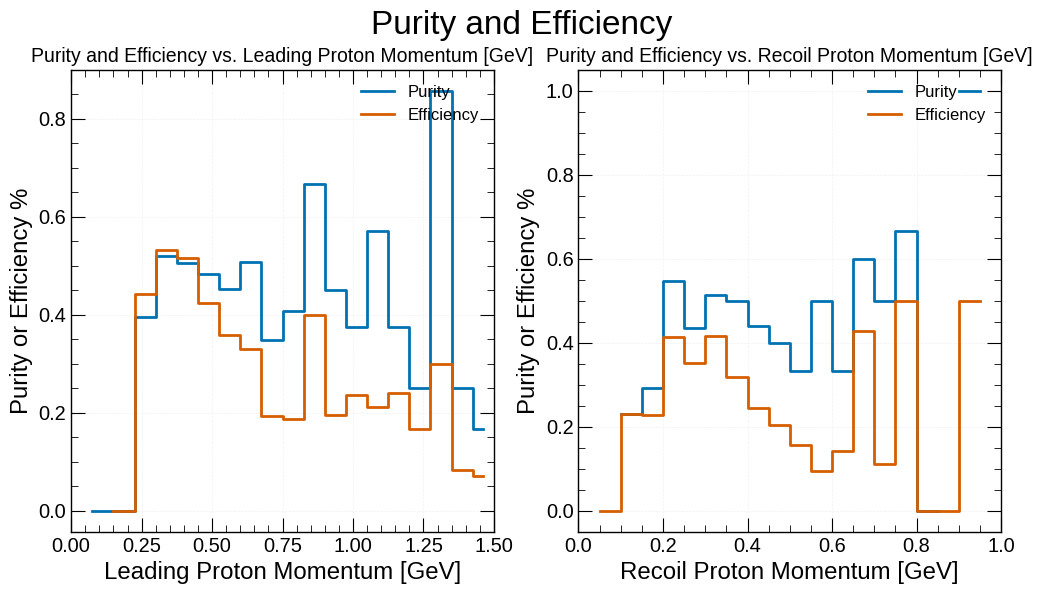

In [91]:
data = {'signal': reco_event, 'true': true_event, 'true and signal': true_reco_event, 'leading proton p': leading_p_p, 'recoil proton p': recoil_p_p, 'muon p': muon_p, 'nu momentum': true_nu_momentum, 'theta pp': theta_pp}
dfp = pd.DataFrame(data=data)
# All the independent variables are truth rn (momentum, angle)

#Save purity and efficiency values
purity_vals_lpp = []
purity_vals_rpp = []
purity_vals_mu = []
purity_vals_nu = []
purity_vals_theta = []
eff_vals_lpp = []
eff_vals_rpp = []
eff_vals_mu = []
eff_vals_nu = []
eff_vals_theta = []
stat_error_lpp = []
stat_error_rpp = []
stat_error_mu = []
stat_error_nu = []
stat_error_theta = []

#For significance plot
signal_lpp = []
signal_rpp = []
signal_mu = []
signal_nu = []
signal_theta = []
background_lpp = []
background_rpp = []
background_mu = []
background_nu = []
background_theta = []

#Leading proton momentum binning
nbins_lpp = 20
hist_lpp, bin_edges_lpp = np.histogram(leading_p_p, bins=nbins_lpp, range=(0,1.5)) #Create bins based on leading proton momentum
bin_centers_lpp = (bin_edges_lpp[:-1] + bin_edges_lpp[1:])/2
bin_width_lpp = (bin_edges_lpp[-1] + bin_edges_lpp[0])/nbins_lpp
labels_lpp = np.arange(0, nbins_lpp) #Label each bin numerically for leading proton momentum

dfp['bin lpp'] = pd.cut(dfp['leading proton p'], bins=bin_edges_lpp, labels=labels_lpp) #Create a column in df defining the number bin each event is in based on leading proton momentum

#Recoil proton momentum binning
nbins_rpp = 20
hist_rpp, bin_edges_rpp = np.histogram(recoil_p_p, bins=nbins_rpp, range=(0,1.0)) #Create bins based on recoil proton momentum
bin_centers_rpp = (bin_edges_rpp[:-1] + bin_edges_rpp[1:])/2
bin_width_rpp = (bin_edges_rpp[-1] + bin_edges_rpp[0])/nbins_rpp
labels_rpp = np.arange(0, nbins_rpp) #Label each bin numerically for recoil proton momentum

dfp['bin rpp'] = pd.cut(dfp['recoil proton p'], bins=bin_edges_rpp, labels=labels_rpp) #Create a column in df defining the number bin each event is in based on recoil proton momentum

#Muon momentum binning
nbins_mu = 20
hist_mu, bin_edges_mu = np.histogram(muon_p, bins=nbins_mu, range=(0,1.0)) #Create bins based on recoil proton momentum
bin_centers_mu = (bin_edges_mu[:-1] + bin_edges_mu[1:])/2
bin_width_mu = (bin_edges_mu[-1] + bin_edges_mu[0])/nbins_mu
labels_mu = np.arange(0, nbins_mu) #Label each bin numerically for recoil proton momentum

dfp['bin mu'] = pd.cut(dfp['muon p'], bins=bin_edges_mu, labels=labels_mu) #Create a column in df defining the number bin each event is in based on recoil proton momentum

#Neutrino energy binning
nbins_nu = 20
hist_nu, bin_edges_nu = np.histogram(true_nu_momentum, bins=nbins_nu, range=(0,20)) #Create bins based on true neutrino energy
bin_centers_nu = (bin_edges_nu[:-1] + bin_edges_nu[1:])/2
bin_width_nu = (bin_edges_nu[-1] + bin_edges_nu[0])/nbins_nu
labels_nu = np.arange(0, nbins_nu) #Label each bin numerically for true neutrino energy

dfp['bin nu'] = pd.cut(dfp['nu momentum'], bins=bin_edges_nu, labels=labels_nu) #Create a column in df defining the number bin each event is in based on true neutrino energy

#Theta pp binning
nbins_theta = 20
hist_theta, bin_edges_theta = np.histogram(theta_pp, bins=nbins_theta, range=(-1, 1)) #Create bins based on theta pp
bin_centers_theta = (bin_edges_theta[:-1] + bin_edges_theta[1:])/2
bin_width_theta = (bin_edges_theta[-1] + bin_edges_theta[0])/nbins_theta
labels_theta = np.arange(0, nbins_theta) #Label each bin numerically for theta pp

dfp['bin theta'] = pd.cut(dfp['theta pp'], bins=bin_edges_theta, labels=labels_theta) #Create a column in df defining the number bin each event is in based on theta pp

# Loop through each leading proton momentum bin and calculate purity & efficiency
for i in labels_lpp:
    df_bin = dfp[(dfp['bin lpp'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_lpp.append(1/np.sqrt(n_events))

    signal_lpp.append(sum(signal_bin))
    background_lpp.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_lpp.append(np.nan)
    else:
        purity_vals_lpp.append(sum(true_signal_bin)/sum(signal_bin))
    
    if sum(true_bin) == 0:
        eff_vals_lpp.append(np.nan)
    else:
        eff_vals_lpp.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each recoil proton momentum bin and calculate purity & efficiency
for i in labels_rpp:
    df_bin = dfp[(dfp['bin rpp'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_rpp.append(1/np.sqrt(n_events))

    signal_rpp.append(sum(signal_bin))
    background_rpp.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_rpp.append(np.nan)
    else:
        purity_vals_rpp.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_rpp.append(np.nan)
    else:
        eff_vals_rpp.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each muon momentum bin and calculate purity and efficiency
for i in labels_mu:
    df_bin = dfp[(dfp['bin mu'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_mu.append(1/np.sqrt(n_events))

    signal_mu.append(sum(signal_bin))
    background_mu.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_mu.append(np.nan)
    else:
        purity_vals_mu.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_mu.append(np.nan)
    else:
        eff_vals_mu.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each true neutrino energy bin and calculate purity and efficiency
for i in labels_nu:
    df_bin = dfp[(dfp['bin nu'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_nu.append(1/np.sqrt(n_events))

    signal_nu.append(sum(signal_bin))
    background_nu.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_nu.append(np.nan)
    else:
        purity_vals_nu.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_nu.append(np.nan)
    else:
        eff_vals_nu.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each angle between proton bin and calculate purity and efficiency FOR LATER
for i in labels_theta:
    df_bin = dfp[(dfp['bin theta'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_theta.append(1/np.sqrt(n_events))

    signal_theta.append(sum(signal_bin))
    background_theta.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_theta.append(np.nan)
    else:
        purity_vals_theta.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_theta.append(np.nan)
    else:
        eff_vals_theta.append(sum(true_signal_bin)/sum(true_bin))

# Delete the last bin value because we are plotting each step from the leftmost bin edge
lpp_values = np.delete(bin_edges_lpp, nbins_lpp)
rpp_values = np.delete(bin_edges_rpp, nbins_rpp)
mu_values = np.delete(bin_edges_mu, nbins_mu)
nu_values = np.delete(bin_edges_nu, nbins_nu)
theta_values = np.delete(bin_edges_theta, nbins_theta)


#Purity and Efficiency Plots
fig, ax = plt.subplots(1, 2, figsize=(12,6))
fig.suptitle('Purity and Efficiency', fontsize=24)
#Plot purity and efficiency vs. leading proton momentum
#ax[0].errorbar(bin_centers_lpp, purity_vals_lpp, xerr=bin_width_lpp/2, yerr=stat_error_lpp, fmt='.', label='Purity', elinewidth=2, capsize=3)
#ax[0].errorbar(bin_centers_lpp, eff_vals_lpp, xerr=bin_width_lpp/2, yerr=stat_error_lpp, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
ax[0].step(bin_centers_lpp, purity_vals_lpp, where='mid', label='Purity', color='#0072B2')
ax[0].step(bin_centers_lpp, eff_vals_lpp, where='mid', label='Efficiency', color='#D55E00')
ax[0].set_xlabel('Leading Proton Momentum [GeV]')
ax[0].set_ylabel('Purity or Efficiency %')
ax[0].set_title('Purity and Efficiency vs. Leading Proton Momentum [GeV]', fontsize=14)
ax[0].set_xlim(0, 1.5)
ax[0].grid(color='0.95')
ax[0].legend(loc='upper right')
#Plot purity and efficiency vs. recoil proton momentum
#ax[1].errorbar(bin_centers_rpp, purity_vals_rpp, xerr=bin_width_rpp/2, yerr=stat_error_rpp, fmt='.', label='Purity', elinewidth=2, capsize=3)
#ax[1].errorbar(bin_centers_rpp, eff_vals_rpp, xerr=bin_width_rpp/2, yerr=stat_error_rpp, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
ax[1].step(bin_centers_rpp, purity_vals_rpp, where='mid', label='Purity', color='#0072B2')
ax[1].step(bin_centers_rpp, eff_vals_rpp, where='mid', label='Efficiency', color='#D55E00')
ax[1].set_xlabel('Recoil Proton Momentum [GeV]')
ax[1].set_ylabel('Purity or Efficiency %')
ax[1].set_title('Purity and Efficiency vs. Recoil Proton Momentum [GeV]', fontsize=14)
ax[1].set_xlim(0, 1.0)
ax[1].grid(color='0.95')
ax[1].legend(loc='upper right')
"""
#Plot purity and efficiency vs. neutrino energy
#ax[2].errorbar(bin_centers_nu, purity_vals_nu, yerr=stat_error_nu, fmt='.', label='Purity', elinewidth=2, capsize=3)
#ax[2].errorbar(bin_centers_nu, eff_vals_nu, yerr=stat_error_nu, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
ax[2].step(bin_centers_nu, purity_vals_nu, where='mid', label='Purity', color='#0072B2')
ax[2].step(bin_centers_nu, eff_vals_nu, where='mid', label='Efficiency', color='#D55E00')
ax[2].set_xlabel('Neutrino Momentum [GeV]')
ax[2].set_ylabel('Purity or Efficiency %')
ax[2].set_title('Purity and Efficiency vs. Neutrino Momentum [GeV]', fontsize=14)
ax[2].grid(color='0.95')
ax[2].legend(loc='upper right')

#Plot purity and efficiency vs. angle between protons
ax[2].errorbar(bin_centers_theta, purity_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Purity', elinewidth=2, capsize=3)
ax[2].errorbar(bin_centers_theta, eff_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
#xerr=bin_width_theta/2 yerr=stat_error_theta
ax[2].set_xlabel('Angle between Protons')
ax[2].set_ylabel('Purity or Efficiency %')
ax[2].set_title('Purity and Efficiency vs. Angle between Protons', fontsize=14)
ax[2].set_xlim(-1, 1)
ax[2].grid(color='0.95')
ax[2].legend(loc='upper right')
"""
#print(df)

#---------------------------------------------
#Use true and reco energy bins for purity and efficiency
#---------------------------------------------

## Muon start point vs vtx
Reconstructed <br>

N muons: 889
median |start - vertex|: 0.19 cm
fraction within 5 cm:    0.987
mean (dx, dy, dz):       [0.01 0.   0.43] cm


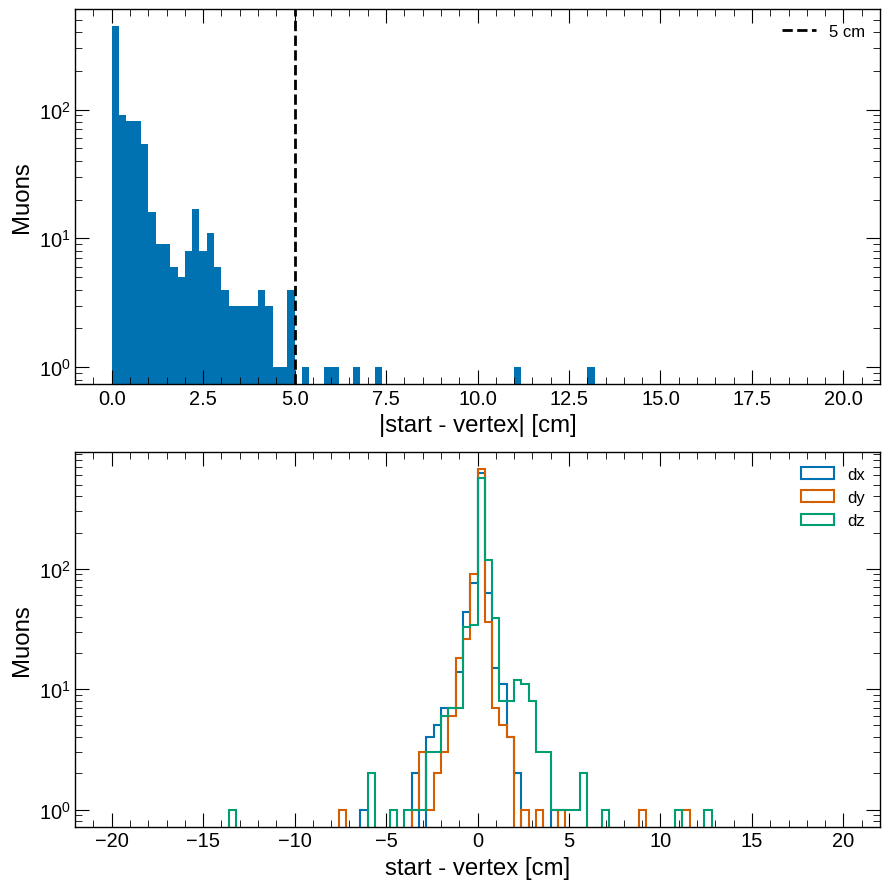

In [92]:
#if reco_pdg_ev[part] == -13 or reco_pdg_ev[part] == 13:
#                mu_start.append([reco_track_start_x_ev[part], reco_track_start_y_ev[part], reco_track_start_z_ev[part]])
#                vtx.append([reco_vtx_x_ev, reco_vtx_y_ev, reco_vtx_z_ev])

mu_start = np.asarray(mu_start, dtype=float)   # shape (N, 3)
vtx      = np.asarray(vtx, dtype=float)        # shape (N, 3)

# Drop any entries with NaN coordinates (e.g. failed track reconstruction)
good = np.isfinite(mu_start).all(axis=1) & np.isfinite(vtx).all(axis=1)
mu_start, vtx = mu_start[good], vtx[good]

# Difference, start - vertex, so the sign of each component is meaningful
diff = mu_start - vtx                          # columns: dx, dy, dz
dist = np.linalg.norm(diff, axis=1)            # 3D distance

print(f"N muons: {len(dist)}")
print(f"median |start - vertex|: {np.median(dist):.2f} cm")
print(f"fraction within 5 cm:    {np.mean(dist < 5.0):.3f}")
print(f"mean (dx, dy, dz):       {diff.mean(axis=0).round(2)} cm")

fig, ax = plt.subplots(2, figsize=(9, 9))

# 1. 3D distance (log y so the tail is visible)
ax[0].hist(dist, bins=100, range=(0, 20))
ax[0].axvline(5.0, color="k", ls="--", label="5 cm")
ax[0].set_yscale("log")
ax[0].set_xlabel("|start - vertex| [cm]")
ax[0].set_ylabel("Muons")
ax[0].legend()

# 2. Components, to see which axis drives any offset
for i, name in enumerate(["dx", "dy", "dz"]):
    ax[1].hist(diff[:, i], bins=100, range=(-20, 20), histtype="step", label=name)
ax[1].set_yscale("log")
ax[1].set_xlabel("start - vertex [cm]")
ax[1].set_ylabel("Muons")
ax[1].legend()

plt.tight_layout()
plt.show()


## Event Modes

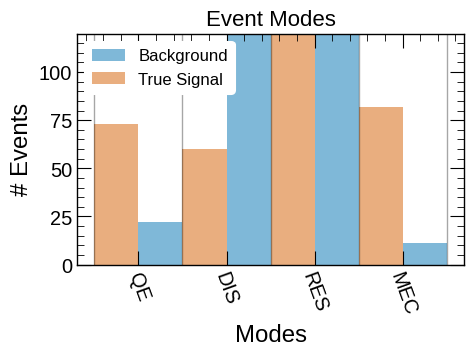

In [93]:
bg_df = df.loc[(df["truth_passes"] == 0) & (df["reco_passes"] == 1), \
    ["event_number", "mode"]].drop_duplicates(subset=['event_number'])

signal_df = df.loc[(df["truth_passes"] == 1) & (df["reco_passes"] == 1), \
    ["event_number", "mode"]].drop_duplicates(subset=['event_number'])

mode_res_bg = df.loc[(df["mode"] == 4) & (df["reco_passes"] == 1) & (df["truth_passes"] == 0), ["event_number", "true_pdg", "reco_pdg"]]
# What are the background RES events?
#print(mode_res_bg[["event_number", "true_pdg", "reco_pdg"]].head(20))


# Shift the mode numbers over to show only the relevant modes. Do any analysis before this, this is only for plot
# Signal mode numbers higher by 1 for alignment purposes
bg_df['mode'] = bg_df['mode'].replace({3: 2, 4: 3, 10: 4})
signal_df['mode'] = signal_df['mode'].replace({3: 2, 4: 3, 10: 4})

# 1 = QE, 2 = DIS, 3 = RES, 4 = MEC
# Signal: QE - 0-0.5
xline = [0, 1, 2, 3, 4]

#Make a histogram of the background event modes
fig = plt.figure(figsize=(5,3))
n_bg, bins_bg, edges_bg = plt.hist(bg_df["mode"] - 0.5, bins=np.arange(0.0, 4.5, 0.5), density=False, alpha=0.5, label='Background')
n_sig, bins_sig, edges_sig = plt.hist(signal_df["mode"] - 1.0, bins=np.arange(0.0, 4.5, 0.5), density=False, alpha=0.5, label='True Signal')
#plt.xticks(np.arange(1.25, 12.25, 1.0), ['QE', 'Kaon', 'DIS', 'RES', 'COH', 'Diff', 'NueElast', 'InvMuDec', 'NuGamma', 'MEC', 'CohElast'], rotation=290)
plt.xticks(np.arange(0.5, 4.5, 1.0), ['QE', 'DIS', 'RES', 'MEC'], rotation=290)
plt.tick_params(axis='x', which='minor', bottom=False)
for x in xline:
    plt.axvline(x=x, color='black', linewidth=1, alpha=0.35)
plt.xlabel("Modes")
plt.ylabel("# Events")
plt.ylim(0, 120)
plt.title("Event Modes", fontsize=16)
plt.legend(frameon=True, facecolor='white', edgecolor='white', framealpha=1)
plt.show()

## Significance

/tmp/ipykernel_96356/127612411.py:2: RuntimeWarning: invalid value encountered in divide
  sig_lpp = np.array(signal_lpp)/(np.sqrt(np.array(signal_lpp) + np.array(background_lpp)))
/tmp/ipykernel_96356/127612411.py:3: RuntimeWarning: invalid value encountered in divide
  sig_rpp = np.array(signal_rpp)/(np.sqrt(np.array(signal_rpp) + np.array(background_rpp)))
/tmp/ipykernel_96356/127612411.py:4: RuntimeWarning: invalid value encountered in divide
  sig_nu = np.array(signal_nu)/(np.sqrt(np.array(signal_nu) + np.array(background_nu)))


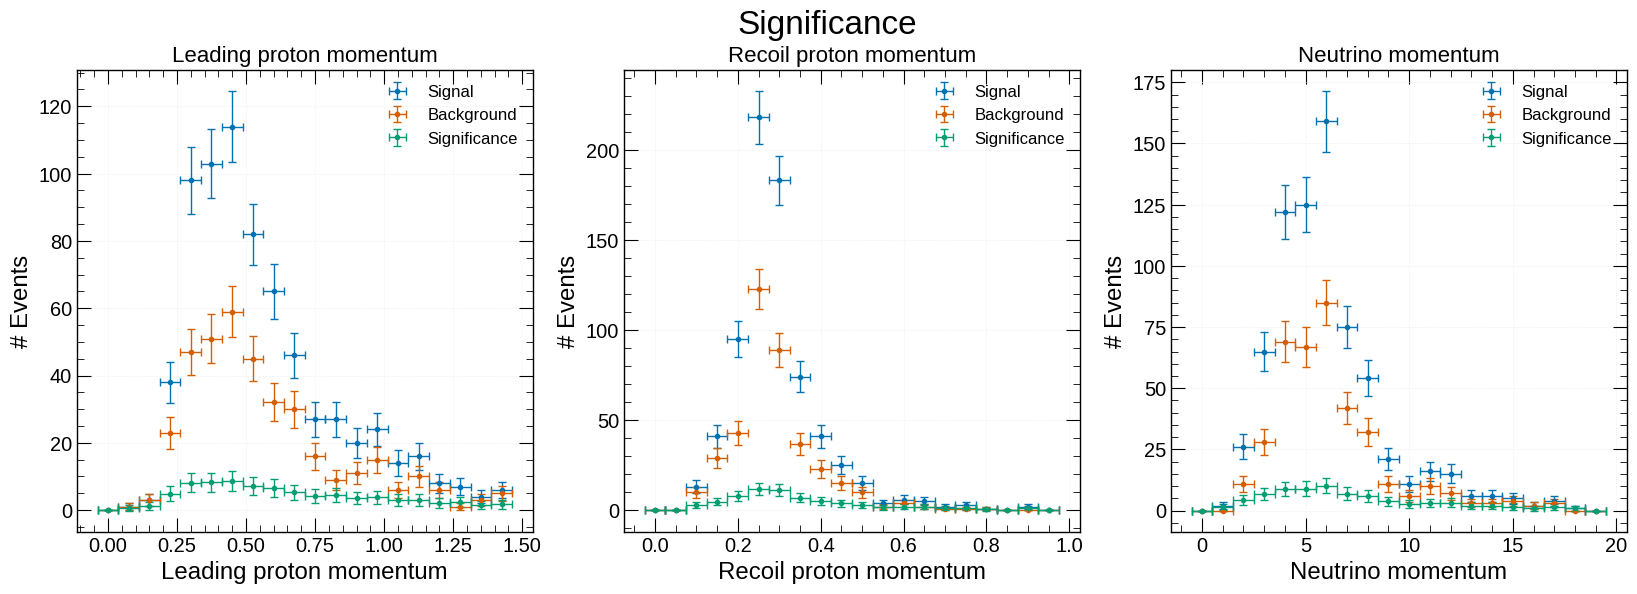

Leading proton momentum cutoff:  0.44999999999999996
Recoil proton momentum cutoff:  0.25
Neutrino momentum cutoff:  6.0


In [94]:
#Plot signal, background, and significance vs. proton momentum, muon momentum, and neutrino energy
sig_lpp = np.array(signal_lpp)/(np.sqrt(np.array(signal_lpp) + np.array(background_lpp)))
sig_rpp = np.array(signal_rpp)/(np.sqrt(np.array(signal_rpp) + np.array(background_rpp)))
sig_nu = np.array(signal_nu)/(np.sqrt(np.array(signal_nu) + np.array(background_nu)))

np.nan_to_num(sig_lpp, False, nan=0.0, posinf=0.0, neginf=0.0)
np.nan_to_num(sig_rpp, False, nan=0.0, posinf=0.0, neginf=0.0)
np.nan_to_num(sig_nu, False, nan=0.0, posinf=0.0, neginf=0.0)

fig, ax = plt.subplots(1, 3, figsize=(20,6))
fig.suptitle('Significance', fontsize=24)
#Leading Proton Momentum
ax[0].errorbar(lpp_values, signal_lpp, xerr=bin_width_lpp/2, yerr=(np.sqrt(signal_lpp)), fmt='.', label='Signal', elinewidth=1, capsize=3)
ax[0].errorbar(lpp_values, background_lpp, xerr=bin_width_lpp/2, yerr=(np.sqrt(background_lpp)), fmt='.', label='Background', elinewidth=1, capsize=3)
ax[0].errorbar(lpp_values, sig_lpp, xerr=bin_width_lpp/2, yerr=(np.sqrt(sig_lpp)), fmt='.', label='Significance', elinewidth=1, capsize=3)
ax[0].set_xlabel('Leading proton momentum')
ax[0].set_ylabel('# Events')
ax[0].set_title('Leading proton momentum', fontsize=16)
ax[0].legend()
ax[0].grid(color='0.95')
#Recoil Proton Momentum
ax[1].errorbar(rpp_values, signal_rpp, xerr=bin_width_rpp/2, yerr=(np.sqrt(signal_rpp)), fmt='.', label='Signal', elinewidth=1, capsize=3)
ax[1].errorbar(rpp_values, background_rpp, xerr=bin_width_rpp/2, yerr=(np.sqrt(background_rpp)), fmt='.', label='Background', elinewidth=1, capsize=3)
ax[1].errorbar(rpp_values, sig_rpp, xerr=bin_width_rpp/2, yerr=(np.sqrt(sig_rpp)), fmt='.', label='Significance', elinewidth=1, capsize=3)
ax[1].set_xlabel('Recoil proton momentum')
ax[1].set_ylabel('# Events')
ax[1].set_title('Recoil proton momentum', fontsize=16)
ax[1].legend()
ax[1].grid(color='0.95')
#Neutrino Momentum
ax[2].errorbar(nu_values, signal_nu, xerr=bin_width_nu/2, yerr=(np.sqrt(signal_nu)), fmt='.', label='Signal', elinewidth=1, capsize=3)
ax[2].errorbar(nu_values, background_nu, xerr=bin_width_nu/2, yerr=(np.sqrt(background_nu)), fmt='.', label='Background', elinewidth=1, capsize=3)
ax[2].errorbar(nu_values, sig_nu, xerr=bin_width_nu/2, yerr=(np.sqrt(sig_nu)), fmt='.', label='Significance', elinewidth=1, capsize=3)
ax[2].set_xlabel('Neutrino momentum')
ax[2].set_ylabel('# Events')
ax[2].set_title('Neutrino momentum', fontsize=16)
ax[2].legend()
ax[2].grid(color='0.95')

plt.show()

print("Leading proton momentum cutoff: ", lpp_values[np.nanargmax(sig_lpp)])
print("Recoil proton momentum cutoff: ", rpp_values[np.nanargmax(sig_rpp)])
print("Neutrino momentum cutoff: ", nu_values[np.nanargmax(sig_nu)])

## Proton Momentum truth vs. reco plots

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_96356/2303924085.py:27: SyntaxWarning: invalid escape sequence '\m'
  plt.suptitle("True vs. Reco Proton Momentum for CC 2p1$\mu$0$\pi$ Events", y=0.92, fontsize=16)


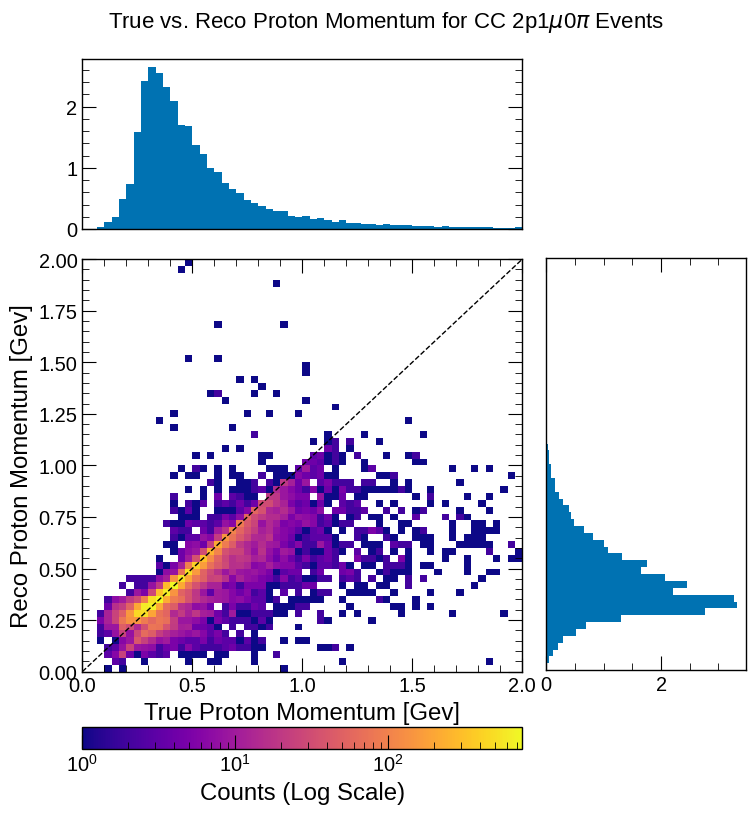

In [95]:
#2D histogram with 1D projections
fig = plt.figure(figsize=(8,10))
left, width, bottom, height = 0.12, 0.55, 0.12, 0.55
bottom_h = left_h = left + width + 0.03
#Dimensions
dim_2dhist = [left, bottom, width, height] #Dimensions of 2d hist
dim_1dhistx = [left, bottom_h, width, 0.17] #Dimensions of 1d x hist
dim_1dhisty = [left_h, bottom + 0.139, 0.25, height-0.138] #Dimensions of 1d y hist
#Make the plots
ax2dhist = plt.axes(dim_2dhist) #2d hist plot
ax1dhistx = plt.axes(dim_1dhistx) #1d x hist plot
ax1dhisty = plt.axes(dim_1dhisty) #1d y hist plot
#Plot histograms
_,_,_,im =ax2dhist.hist2d(hist_proton_truep, hist_proton_recop, bins=60, range=((0,2),(0,2)), norm=colors.LogNorm(), cmap='plasma')
ax1dhistx.hist(true_proton_p, bins=60, range=(0,2), density=True, color='#0072B2')
ax1dhisty.hist(reco_proton_p, bins=60, range=(0,2), density=True, orientation='horizontal', color='#0072B2')
ax1dhistx.set_xlim(0,2)
ax1dhisty.set_ylim(0,2)
#Make it pretty
ax2dhist.set_xlabel("True Proton Momentum [Gev]")
ax2dhist.set_ylabel("Reco Proton Momentum [Gev]")
ax1dhistx.get_xaxis().set_visible(False)
ax1dhisty.get_yaxis().set_visible(False)
ax2dhist.plot([0, 2], [0, 2], color="black", linestyle="--", linewidth=1, label="y = x")
cbar = plt.colorbar(im, ax=ax2dhist, pad=0.1, location='bottom')
cbar.set_label('Counts (Log Scale)')
plt.suptitle("True vs. Reco Proton Momentum for CC 2p1$\mu$0$\pi$ Events", y=0.92, fontsize=16)
plt.show()


## Purity and Efficiency vs. Cuts 

Scatter plot showing the progression of the purity and efficiency as each subsequent cut is added

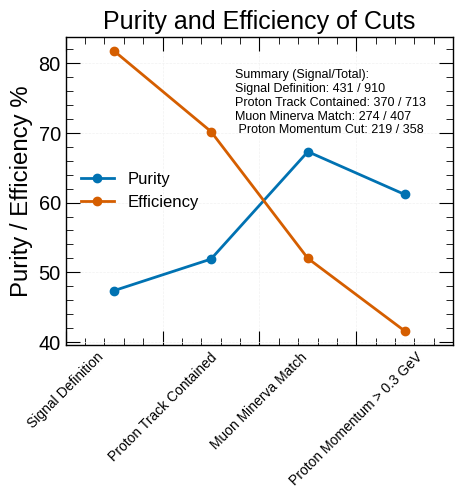

In [96]:
#Not using the cuts with momentum, those dropped the purity compared to the minerva matching
#Cut 1: vertex within volume, Np=2, Nmu=1, Npi=0
#Cut 2: Proton track fully contained
#Cut 3: Muon track punches out the back of minerva
#Cut 4: Proton > 0.3 GeV
purity_cuts = [47.36, 51.89, 67.32, 61.17]
efficiency_cuts = [81.78, 70.21, 51.99, 41.56]
phase = ['Signal Definition', 'Proton Track Contained', 'Muon Minerva Match', 'Proton Momentum > 0.3 GeV']
x_plot = [1, 2, 3, 4]
phase_num = [0.5, 1.5, 2.5, 3.5]

plt.figure(figsize=(5,4))
plt.plot(x_plot, purity_cuts, marker='o', label='Purity', linewidth=2)
plt.plot(x_plot, efficiency_cuts, marker='o', label='Efficiency', linewidth=2)
plt.xticks(phase_num, phase, rotation=45, fontsize=10)
plt.xlim(0.5,4.5)
plt.ylabel('Purity / Efficiency %')
plt.title('Purity and Efficiency of Cuts', fontsize=18)
plt.grid(color='0.95')
plt.legend(loc='center left')
plt.text(2.25, 70, "Summary (Signal/Total): \nSignal Definition: 431 / 910 \nProton Track Contained: 370 / 713 \n" \
"Muon Minerva Match: 274 / 407 \n Proton Momentum Cut: 219 / 358", color='black', fontsize=9)
plt.show()

## Proton ID Purity vs. truth and reco proton momentum
purity(bin) = N(true_pdg == 2212 AND reco_pdg == 2212 in that momentum bin) / N(reco_pdg == 2212 in that momentum bin)

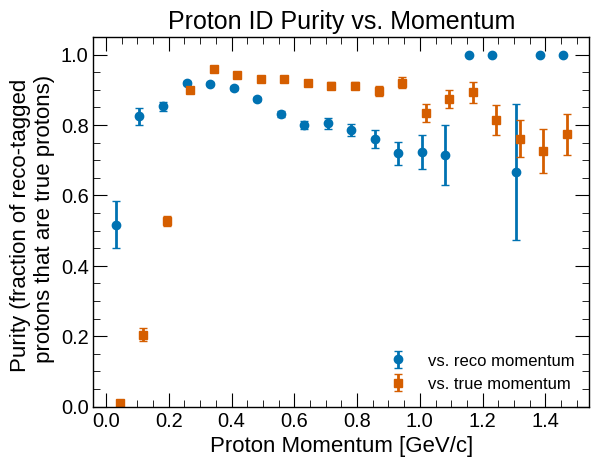

In [97]:
NBINS = 20
XLO, XHI = 0.0, 1.5   # GeV/c

reco_proton = df["reco_pdg"] == 2212
true_match = df["true_pdg"] == 2212

pmag_reco = df.loc[reco_proton, "reco_pmag"].to_numpy(dtype=float)
pmag_true = df.loc[reco_proton, "true_pmag"].to_numpy(dtype=float)
is_true_proton = true_match.loc[reco_proton].to_numpy()

edges = np.linspace(XLO, XHI, NBINS + 1)
centers = 0.5 * (edges[:-1] + edges[1:])

# ----------------------------------------------------------------------
# Purity & binomial error per bin, binning reco-tagged protons by 'pmag'
# ----------------------------------------------------------------------
def purity_curve(pmag, is_true_proton, edges, nbins):
    bin_idx = np.searchsorted(edges, pmag, side="right") - 1

    purity = np.full(nbins, np.nan)
    err = np.full(nbins, np.nan)
    n_per_bin = np.zeros(nbins, dtype=int)

    for b in range(nbins):
        sel = bin_idx == b
        n = sel.sum()
        n_per_bin[b] = n
        if n == 0:
            continue
        k = is_true_proton[sel].sum()
        p = k / n
        purity[b] = p
        # binomial standard error; 0 when the bin is 100% pure (or empty)
        # rather than reporting a misleadingly small nonzero error
        err[b] = np.sqrt(p * (1 - p) / n) if 0 < p < 1 else 0.0

    return purity, err, n_per_bin


purity_reco, err_reco, n_reco = purity_curve(pmag_reco, is_true_proton, edges, NBINS)
purity_true, err_true, n_true = purity_curve(pmag_true, is_true_proton, edges, NBINS)

fig, ax = plt.subplots()

# small x-offset so the two sets of points/error bars don't sit on top of each other
dx = (edges[1] - edges[0]) * 0.08

ax.errorbar(centers - dx, purity_reco, yerr=err_reco, fmt="o", color="#0072B2",
            capsize=3, label="vs. reco momentum")
ax.errorbar(centers + dx, purity_true, yerr=err_true, fmt="s", color="#D55E00",
            capsize=3, label="vs. true momentum")

ax.set_xlabel("Proton Momentum [GeV/c]", fontsize=16)
ax.set_ylabel("Purity (fraction of reco-tagged \n protons that are true protons)",
              fontsize=16)
ax.set_ylim(0, 1.05)
ax.set_title("Proton ID Purity vs. Momentum", fontsize=18)
ax.legend()
plt.show()

## Kinematics
Leading proton momentum <br>
Recoil proton momentum <br>
Muon momentum <br>
Angle between protons <br>
Angle between muon and proton pair <br>

Number of true events with >=2 protons: 1027
Number of reco events with >=2 protons: 1046


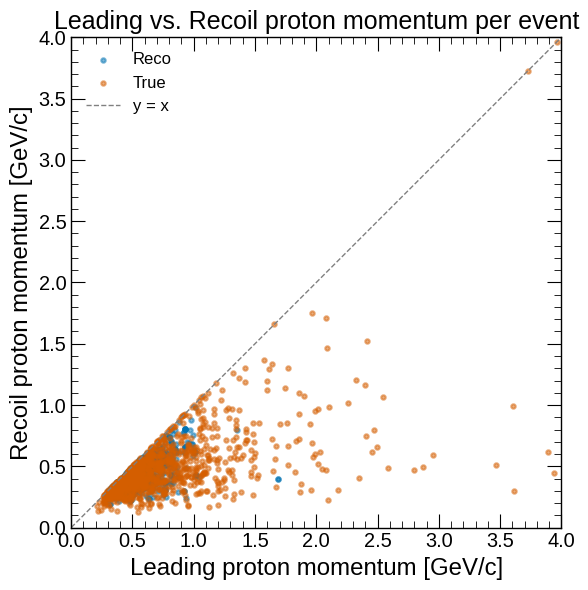

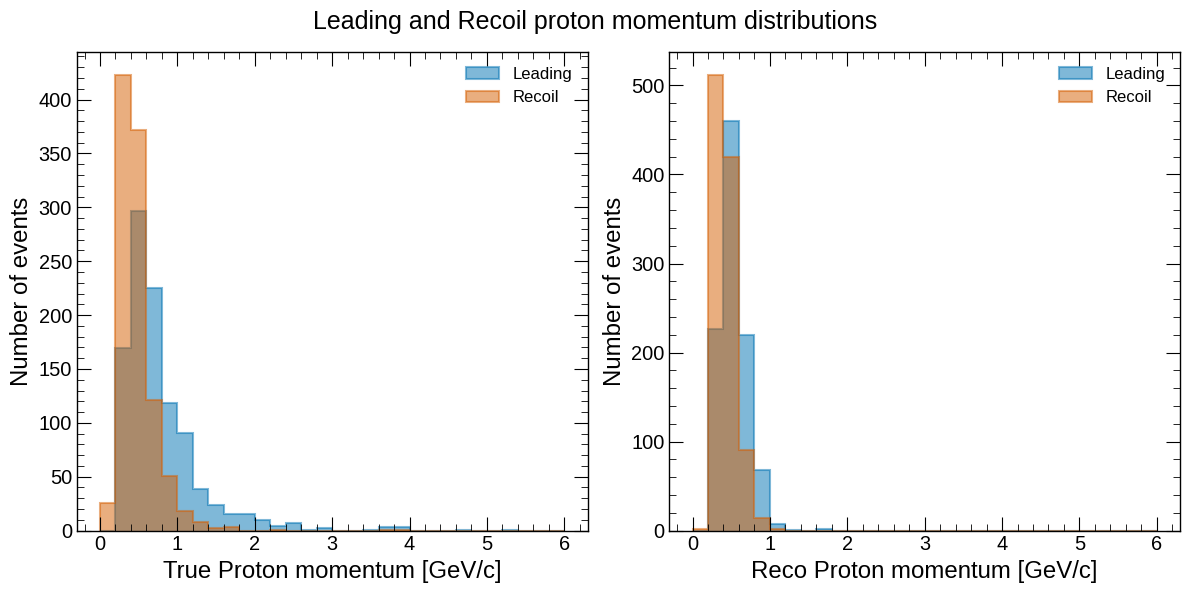

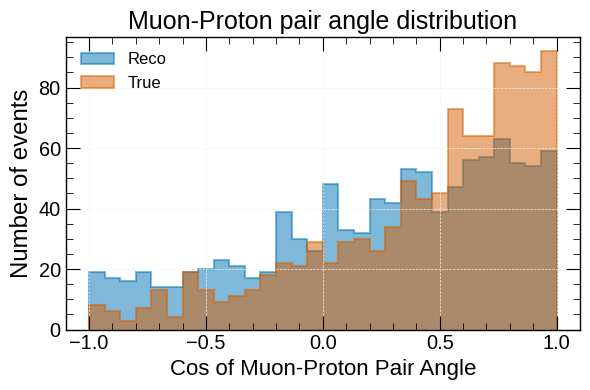

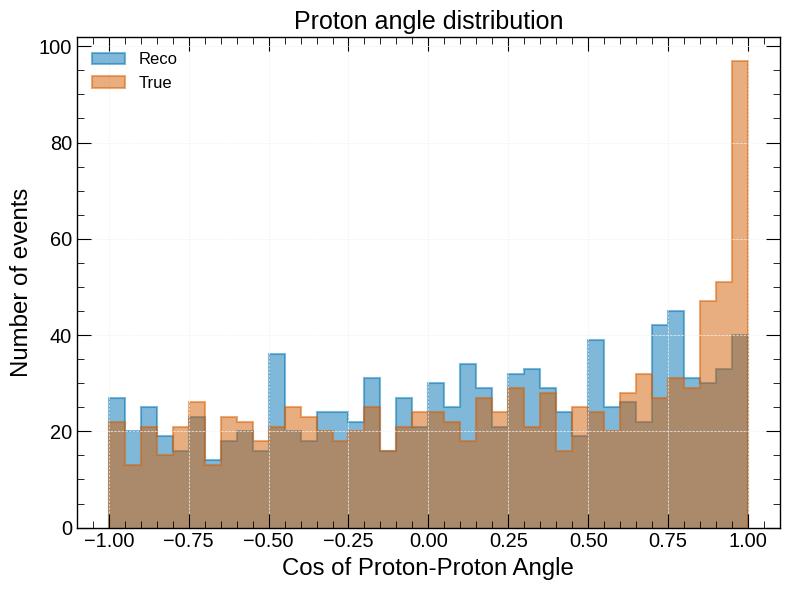

In [98]:
# ----------------------------------------------------------------------
# Truth level kinematics for events that pass truth cuts
# Merge leading proton, recoil proton, and muon momentum dataframes
# ----------------------------------------------------------------------

rank1_true = df.loc[(df["true_proton_rank"] == 1) & (df["truth_passes"] == 1), ["event_number", "true_pmag", "true_px", "true_py", "true_pz"]]
rank2_true = df.loc[(df["true_proton_rank"] == 2) & (df["truth_passes"] == 1), ["event_number", "true_pmag", "true_px", "true_py", "true_pz"]]
muon_true = df.loc[(abs(df["true_pdg"]) == 13) & (df["truth_passes"] == 1), ["event_number", "true_pmag", "true_px", "true_py", "true_pz", "true_pdg"]]

muon_true = muon_true.rename(columns={
    "true_pmag": "true_pmag_muon",
    "true_px": "true_px_muon",
    "true_py": "true_py_muon",
    "true_pz": "true_pz_muon",
})

merged_true = pd.merge(rank1_true, rank2_true, on="event_number", suffixes=("_rank1", "_rank2"))
merged_true = pd.merge(merged_true, muon_true, on="event_number")

# Check
#print(merged_true.head(10))

print(f"Number of true events with >=2 protons: {len(merged_true)}")


# ----------------------------------------------------------------------
# Reco level kinematics for events that pass reco cuts
# Merge leading proton, recoil proton, and muon momentum dataframes
# ----------------------------------------------------------------------
rank1_reco = df.loc[(df["reco_proton_rank"] == 1) & (df["reco_passes"] == 1), ["event_number", "reco_pmag", "reco_px", "reco_py", "reco_pz"]]
rank2_reco = df.loc[(df["reco_proton_rank"] == 2) & (df["reco_passes"] == 1), ["event_number", "reco_pmag", "reco_px", "reco_py", "reco_pz"]]
muon_reco = df.loc[(abs(df["reco_pdg"]) == 13) & (df["reco_passes"] == 1), ["event_number", "reco_pmag", "reco_px", "reco_py", "reco_pz", "reco_pdg"]]

muon_reco = muon_reco.rename(columns={
    "reco_pmag": "reco_pmag_muon",
    "reco_px": "reco_px_muon",
    "reco_py": "reco_py_muon",
    "reco_pz": "reco_pz_muon",
})

merged_reco = pd.merge(rank1_reco, rank2_reco, on="event_number", suffixes=("_rank1", "_rank2"))
merged_reco = pd.merge(merged_reco, muon_reco, on="event_number")

# Check
#print(merged_reco.head(10))

print(f"Number of reco events with >=2 protons: {len(merged_reco)}")

# ----------------------------------------------------------------------
# Leading vs. Recoil Proton Momentum
# ----------------------------------------------------------------------
plt.figure(figsize=(6, 6))
plt.scatter(merged_reco["reco_pmag_rank1"], merged_reco["reco_pmag_rank2"], s=10, alpha=0.5, label='Reco')
plt.scatter(merged_true["true_pmag_rank1"], merged_true["true_pmag_rank2"], s=10, alpha=0.5, label='True')
plt.xlabel("Leading proton momentum [GeV/c]")
plt.ylabel("Recoil proton momentum [GeV/c]")
plt.title("Leading vs. Recoil proton momentum per event", fontsize=18)

# Optional: force equal aspect and draw the y=x line, since rank2 <= rank1 always
max_p = 4 # Max momentum on x and y axis
plt.plot([0, max_p], [0, max_p], color="gray", linestyle="--", linewidth=1, label="y = x")
plt.xlim(0, max_p)
plt.ylim(0, max_p)
plt.gca().set_aspect("equal")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# Separate truth & reco histograms for leading & recoil proton momenta
# ----------------------------------------------------------------------
nbins_true_pmag = 30
hist_true_pmag, bin_edges_true_pmag = np.histogram(merged_true["true_pmag_rank1"], bins=nbins_true_pmag, range=(0, 6))
bin_centers_true_pmag = (bin_edges_true_pmag[:-1] + bin_edges_true_pmag[1:])/2
bin_width_true_pmag = (bin_edges_true_pmag[-1] + bin_edges_true_pmag[0])/nbins_true_pmag
labels_true_pmag = np.arange(0, nbins_true_pmag) 

hist_true_pmag_rank2, bin_edges_true_pmag_rank2 = np.histogram(merged_true["true_pmag_rank2"], bins=nbins_true_pmag, range=(0, 6))
bin_centers_true_pmag_rank2 = (bin_edges_true_pmag_rank2[:-1] + bin_edges_true_pmag_rank2[1:])/2
bin_width_true_pmag_rank2 = (bin_edges_true_pmag_rank2[-1] + bin_edges_true_pmag_rank2[0])/nbins_true_pmag

nbins_reco_pmag = 30
hist_reco_pmag, bin_edges_reco_pmag = np.histogram(merged_reco["reco_pmag_rank1"], bins=nbins_reco_pmag, range=(0, 6))
bin_centers_reco_pmag = (bin_edges_reco_pmag[:-1] + bin_edges_reco_pmag[1:])/2
bin_width_reco_pmag = (bin_edges_reco_pmag[-1] + bin_edges_reco_pmag[0])/nbins_reco_pmag
labels_reco_pmag = np.arange(0, nbins_reco_pmag) 

hist_reco_pmag_rank2, bin_edges_reco_pmag_rank2 = np.histogram(merged_reco["reco_pmag_rank2"], bins=nbins_reco_pmag, range=(0, 6))
bin_centers_reco_pmag_rank2 = (bin_edges_reco_pmag_rank2[:-1] + bin_edges_reco_pmag_rank2[1:])/2
bin_width_reco_pmag_rank2 = (bin_edges_reco_pmag_rank2[-1] + bin_edges_reco_pmag_rank2[0])/nbins_reco_pmag

# Plot as two separate plots in same figure
# Error bar has statistical errors
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
#ax[1].errorbar(bin_centers_reco_pmag, hist_reco_pmag, xerr=bin_width_reco_pmag/2, yerr=np.sqrt(hist_reco_pmag), fmt='.', label='Leading proton reco', elinewidth=1, capsize=3)
#ax[1].errorbar(bin_centers_reco_pmag_rank2, hist_reco_pmag_rank2, xerr=bin_width_reco_pmag_rank2/2, yerr=np.sqrt(hist_reco_pmag_rank2), fmt='.', label='Recoil proton reco', elinewidth=1, capsize=3)
ax[1].stairs(hist_reco_pmag, bin_edges_reco_pmag, fill=True, color='#0072B2', alpha=0.5, edgecolor='#0072B2', linewidth=1.5, linestyle='-', label='Leading')
ax[1].stairs(hist_reco_pmag_rank2, bin_edges_reco_pmag_rank2, fill=True, color='#D55E00', alpha=0.5, edgecolor='#D55E00', linewidth=1.5, linestyle='-', label='Recoil')
#ax[0].errorbar(bin_centers_true_pmag, hist_true_pmag, xerr=bin_width_true_pmag/2, yerr=np.sqrt(hist_true_pmag), fmt='.', label='Leading proton true', elinewidth=1, capsize=3)
#ax[0].errorbar(bin_centers_true_pmag_rank2, hist_true_pmag_rank2, xerr=bin_width_true_pmag_rank2/2, yerr=np.sqrt(hist_true_pmag_rank2), fmt='.', label='Recoil proton true', elinewidth=1, capsize=3)
ax[0].stairs(hist_true_pmag, bin_edges_true_pmag, fill=True, color='#0072B2', alpha=0.5, edgecolor='#0072B2', linewidth=1.5, linestyle='-', label='Leading')
ax[0].stairs(hist_true_pmag_rank2, bin_edges_true_pmag_rank2, fill=True, color='#D55E00', alpha=0.5, edgecolor='#D55E00', linewidth=1.5, linestyle='-', label='Recoil')
ax[0].set_xlabel("True Proton momentum [GeV/c]")
ax[0].set_ylabel("Number of events")
ax[1].set_xlabel("Reco Proton momentum [GeV/c]")
ax[1].set_ylabel("Number of events")
ax[0].legend()
ax[1].legend()
plt.suptitle("Leading and Recoil proton momentum distributions", fontsize=18)
plt.legend()
plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# Proton-Proton angle and Muon-Proton Pair angle distributions
# ----------------------------------------------------------------------
muon_proton_angles_true = []
proton_angle_true = []

for index, row in merged_true.iterrows():
    proton1 = [row["true_px_rank1"], row["true_py_rank1"], row["true_pz_rank1"]]
    proton2 = [row["true_px_rank2"], row["true_py_rank2"], row["true_pz_rank2"]]
    muon = [row["true_px_muon"], row["true_py_muon"], row["true_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles_true.append(angle)
    proton_angle_true.append(theta(proton1, proton2))

muon_proton_angles_reco = []
proton_angle_reco = []

for index, row in merged_reco.iterrows():
    proton1 = [row["reco_px_rank1"], row["reco_py_rank1"], row["reco_pz_rank1"]]
    proton2 = [row["reco_px_rank2"], row["reco_py_rank2"], row["reco_pz_rank2"]]
    muon = [row["reco_px_muon"], row["reco_py_muon"], row["reco_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles_reco.append(angle)
    proton_angle_reco.append(theta(proton1, proton2))

nbins_muon_proton = 30
hist_muon_proton_true, bin_edges_muon_proton_true = np.histogram(muon_proton_angles_true, bins=nbins_muon_proton, range=(-1, 1))
bin_centers_muon_proton = (bin_edges_muon_proton_true[:-1] + bin_edges_muon_proton_true[1:])/2
bin_width_muon_proton = (bin_edges_muon_proton_true[-1] - bin_edges_muon_proton_true[0]) / nbins_muon_proton

hist_muon_proton_reco, bin_edges_muon_proton_reco = np.histogram(muon_proton_angles_reco, bins=nbins_muon_proton, range=(-1, 1))
bin_centers_muon_proton = (bin_edges_muon_proton_reco[:-1] + bin_edges_muon_proton_reco[1:])/2
bin_width_muon_proton = (bin_edges_muon_proton_reco[-1] - bin_edges_muon_proton_reco[0]) / nbins_muon_proton

# Angle between muon and combined proton vector
plt.figure(figsize=(6, 4))
#plt.errorbar(bin_centers_muon_proton, hist_muon_proton_reco, xerr=bin_width_muon_proton/2, yerr=np.sqrt(hist_muon_proton_reco), fmt='.', label='Muon-Proton pair angle Reco', elinewidth=1, capsize=3)
plt.stairs(hist_muon_proton_reco, bin_edges_muon_proton_reco, fill=True, color='#0072B2', alpha=0.5, edgecolor='#0072B2', linewidth=1.5, linestyle='-', label='Reco')
#plt.errorbar(bin_centers_muon_proton, hist_muon_proton_true, xerr=bin_width_muon_proton/2, yerr=np.sqrt(hist_muon_proton_true), fmt='.', label='Muon-Proton pair angle True', elinewidth=1, capsize=3)
plt.stairs(hist_muon_proton_true, bin_edges_muon_proton_true, fill=True, color='#D55E00', alpha=0.5, edgecolor='#D55E00', linewidth=1.5, linestyle='-', label='True')
plt.xlabel("Cos of Muon-Proton Pair Angle", fontsize=16)
plt.ylabel("Number of events")
plt.title("Muon-Proton pair angle distribution", fontsize=18)
plt.legend()
plt.grid(color='0.95')
plt.tight_layout()
plt.show()


nbins_proton_angle = 40
hist_proton_angle_true, bin_edges_proton_angle_true = np.histogram(proton_angle_true, bins=nbins_proton_angle, range=(-1, 1))
bin_centers_proton_angle_true = (bin_edges_proton_angle_true[:-1] + bin_edges_proton_angle_true[1:])/2
bin_width_proton_angle_true = (bin_edges_proton_angle_true[-1] - bin_edges_proton_angle_true[0]) / nbins_proton_angle

hist_proton_angle_reco, bin_edges_proton_angle_reco = np.histogram(proton_angle_reco, bins=nbins_proton_angle, range=(-1, 1))
bin_centers_proton_angle_reco = (bin_edges_proton_angle_reco[:-1] + bin_edges_proton_angle_reco[1:])/2
bin_width_proton_angle_reco = (bin_edges_proton_angle_reco[-1] - bin_edges_proton_angle_reco[0]) / nbins_proton_angle

# Angle between protons
plt.figure(figsize=(8, 6))
#plt.errorbar(bin_centers_proton_angle_reco, hist_proton_angle_reco, xerr=bin_width_proton_angle_reco/2, yerr=np.sqrt(hist_proton_angle_reco), fmt='.', label='Angle between protons Reco', elinewidth=1, capsize=3)
plt.stairs(hist_proton_angle_reco, bin_edges_proton_angle_reco, fill=True, color='#0072B2', alpha=0.5, edgecolor='#0072B2', linewidth=1.5, linestyle='-', label='Reco')
#plt.errorbar(bin_centers_proton_angle_true, hist_proton_angle_true, xerr=bin_width_proton_angle_true/2, yerr=np.sqrt(hist_proton_angle_true), fmt='.', label='Angle between protons True', elinewidth=1, capsize=3)
plt.stairs(hist_proton_angle_true, bin_edges_proton_angle_true, fill=True, color='#D55E00', alpha=0.5, edgecolor='#D55E00', linewidth=1.5, linestyle='-', label='True')
plt.xlabel("Cos of Proton-Proton Angle")
plt.ylabel("Number of events")
plt.title("Proton angle distribution", fontsize=18)
plt.legend()
plt.grid(color='0.95')
plt.tight_layout()
plt.show()

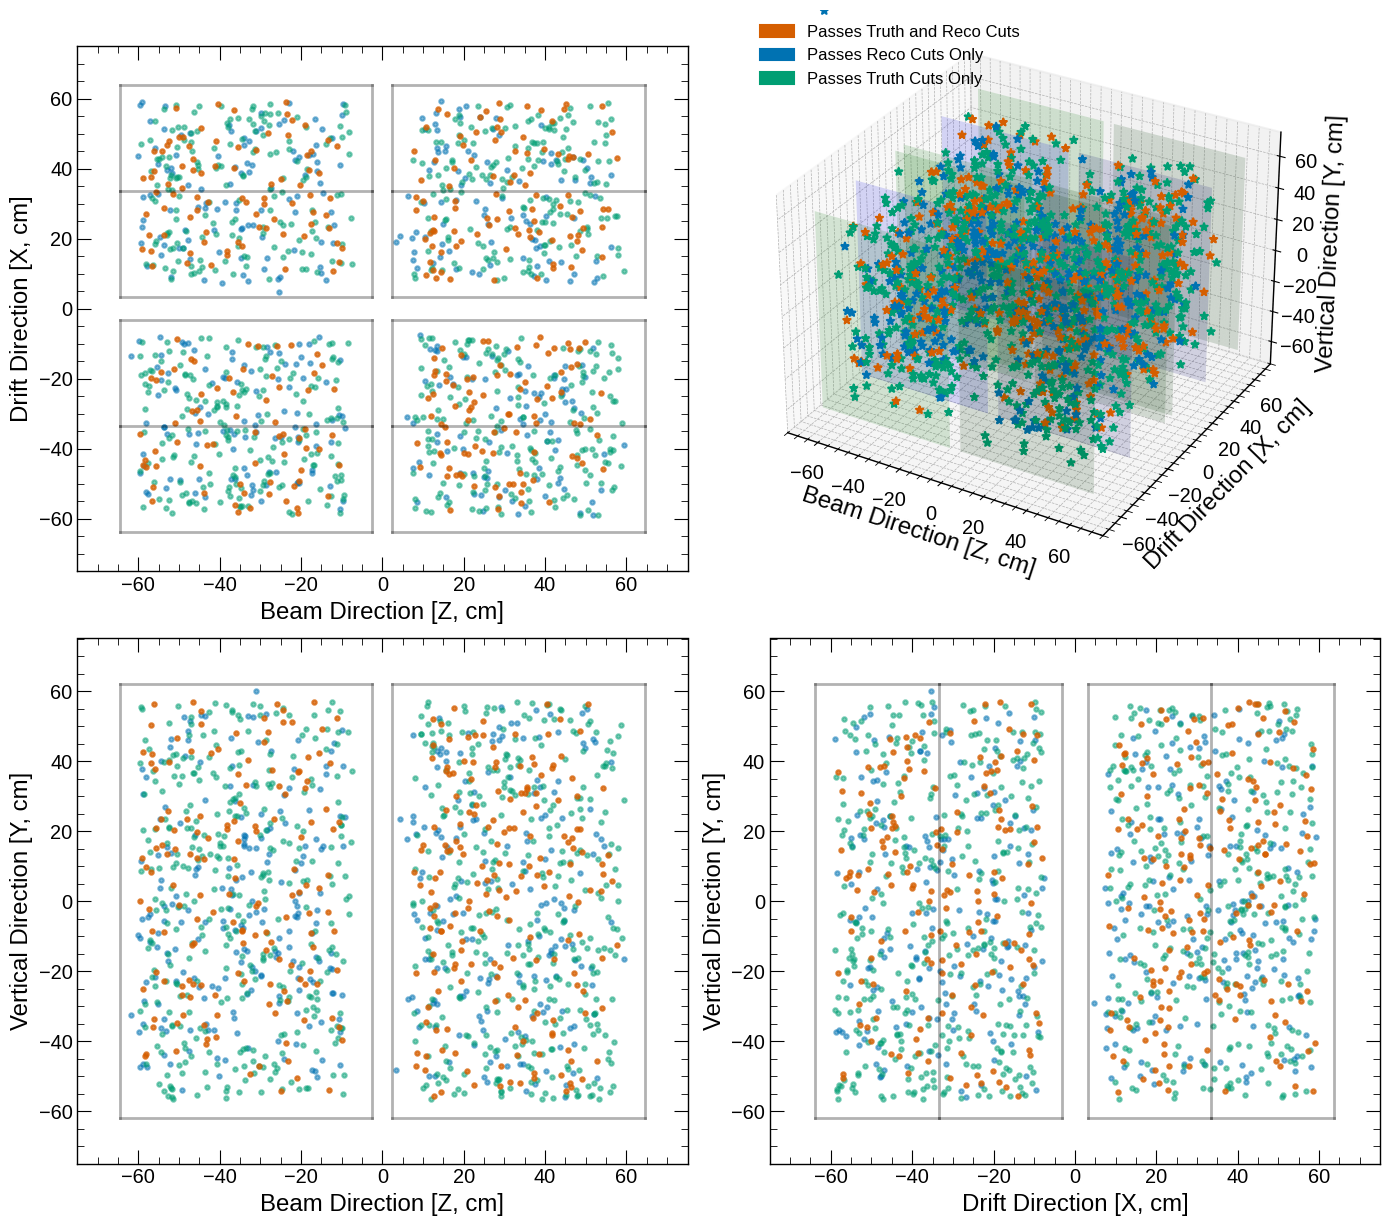

In [99]:
# Vertex locations in 3D. show similar to the 3D event display where there are 3 2D displays and 1 3D display
# File number from which to display events that have passed cuts
color = []

# Reco cuts ONLY (blue), truth cuts ONLY (green), truth and reco (orange)
# select the necessary columns and drop duplicates so there's only 1 row per event 
# we are only looking at event vertex so there's no need for particle specific information
vtx_true = df.loc[(df["truth_passes"] == 1) & (df["reco_passes"] == 0), ["event_number", "true_vtx_x", "true_vtx_y", "true_vtx_z", "reco_vtx_x", "reco_vtx_y", "reco_vtx_z"]].drop_duplicates(subset=['event_number'])
vtx_reco = df.loc[(df["reco_passes"] == 1) & (df["truth_passes"] == 0), ["event_number", "true_vtx_x", "true_vtx_y", "true_vtx_z", "reco_vtx_x", "reco_vtx_y", "reco_vtx_z"]].drop_duplicates(subset=['event_number'])
vtx_both = df.loc[(df["truth_passes"] == 1) & (df["reco_passes"] == 1), ["event_number", "true_vtx_x", "true_vtx_y", "true_vtx_z", "reco_vtx_x", "reco_vtx_y", "reco_vtx_z"]].drop_duplicates(subset=['event_number'])

fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(222, projection='3d')
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(223)
ax3 = fig.add_subplot(224)

def make_cathode_or_anode(y1, y2, z1, z2, x):
    y = np.linspace(y1, y2, 100)
    z = np.linspace(z1, z2, 100)
    Y, Z = np.meshgrid(y, z)
    X = np.full(Y.shape, x)
    return X, Y, Z

# Plot TPC Surfaces
anode_y1s = [-62.076, -62.076, -62.076, -62.076, -62.076, -62.076, -62.076, -62.076]
anode_y2s = [62.076, 62.076, 62.076, 62.076, 62.076, 62.076, 62.076,62.076]
anode_z1s = [2.462, 2.462, 2.462, 2.462, -2.462, -2.462, -2.462, -2.462]
anode_z2s = [2.462+62.076, 2.462+62.076, 2.462+62.076, 2.462+62.076, -2.462-62.076, -2.462-62.076, -2.462-62.076, -2.462-62.076]
anode_xs = [33.5+30.27225, -33.5+30.27225, 33.5-30.27225, -33.5-30.27225, 33.5+30.27225, -33.5+30.27225, 33.5-30.27225, -33.5-30.27225]

cathode_y1s = [-62.076, -62.076, -62.076, -62.076]
cathode_y2s = [62.076, 62.076, 62.076, 62.076]
cathode_z1s = [2.462, 2.462, -2.462, -2.462]
cathode_z2s = [2.462+62.076, 2.462+62.076, -2.462-62.076, -2.462-62.076]
cathode_xs = [33.5, -33.5, 33.5, -33.5]

for i in range(len(cathode_y1s)):
    X_cathode, Y_cathode, Z_cathode = make_cathode_or_anode(cathode_y1s[i], cathode_y2s[i], cathode_z1s[i], cathode_z2s[i], cathode_xs[i])
    ax.plot_surface(Z_cathode,X_cathode,Y_cathode, color='b', alpha=0.15)
for i in range(len(anode_y1s)):
    X_anode, Y_anode, Z_anode = make_cathode_or_anode(anode_y1s[i], anode_y2s[i], anode_z1s[i], anode_z2s[i], anode_xs[i])
    ax.plot_surface(Z_anode,X_anode,Y_anode, color='g', alpha=0.15)

ax.set_xlabel('Beam Direction [Z, cm]')
ax.set_ylabel('Drift Direction [X, cm]')
ax.set_zlabel('Vertical Direction [Y, cm]')

# Plot outlines of detector for projections:
ax1.plot([anode_z1s[0], anode_z1s[0]], [anode_xs[0], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z2s[0], anode_z2s[0]], [anode_xs[0], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z1s[0], anode_z2s[0]], [anode_xs[0], anode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z1s[0], anode_z2s[0]], [cathode_xs[0], cathode_xs[0]], color='k', alpha=0.3)

ax1.plot([anode_z1s[0], anode_z1s[0]], [anode_xs[2], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z2s[0], anode_z2s[0]], [anode_xs[2], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z1s[0], anode_z2s[0]], [anode_xs[2], anode_xs[2]], color='k', alpha=0.3)
#ax1.plot([anode_z1s[0], anode_z2s[0]], [cathode_xs[0], cathode_xs[0]], color='k', alpha=0.3)

ax1.plot([anode_z1s[0], anode_z1s[0]], [anode_xs[1], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z2s[0], anode_z2s[0]], [anode_xs[1], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z1s[0], anode_z2s[0]], [anode_xs[1], anode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z1s[0], anode_z2s[0]], [cathode_xs[1], cathode_xs[1]], color='k', alpha=0.3)

ax1.plot([anode_z1s[0], anode_z1s[0]], [anode_xs[3], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z2s[0], anode_z2s[0]], [anode_xs[3], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z1s[0], anode_z2s[0]], [anode_xs[3], anode_xs[3]], color='k', alpha=0.3)
#ax1.plot([anode_z1s[0], anode_z2s[0]], [cathode_xs[1], cathode_xs[1]], color='k', alpha=0.3)

ax1.plot([anode_z1s[-1], anode_z1s[-1]], [anode_xs[0], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z2s[-1], anode_z2s[-1]], [anode_xs[0], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z1s[-1], anode_z2s[-1]], [anode_xs[0], anode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z1s[-1], anode_z2s[-1]], [cathode_xs[0], cathode_xs[0]], color='k', alpha=0.3)

ax1.plot([anode_z1s[-1], anode_z1s[-1]], [anode_xs[2], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z2s[-1], anode_z2s[-1]], [anode_xs[2], cathode_xs[0]], color='k', alpha=0.3)
ax1.plot([anode_z1s[-1], anode_z2s[-1]], [anode_xs[2], anode_xs[2]], color='k', alpha=0.3)
#ax1.plot([anode_z1s[-1], anode_z2s[-1]], [cathode_xs[0], cathode_xs[0]], color='k', alpha=0.3)

ax1.plot([anode_z1s[-1], anode_z1s[-1]], [anode_xs[1], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z2s[-1], anode_z2s[-1]], [anode_xs[1], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z1s[-1], anode_z2s[-1]], [anode_xs[1], anode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z1s[-1], anode_z2s[-1]], [cathode_xs[1], cathode_xs[1]], color='k', alpha=0.3)

ax1.plot([anode_z1s[-1], anode_z1s[-1]], [anode_xs[3], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z2s[-1], anode_z2s[-1]], [anode_xs[3], cathode_xs[1]], color='k', alpha=0.3)
ax1.plot([anode_z1s[-1], anode_z2s[-1]], [anode_xs[3], anode_xs[3]], color='k', alpha=0.3)
#ax1.plot([anode_z1s[-1], anode_z2s[-1]], [cathode_xs[1], cathode_xs[1]], color='k', alpha=0.3)

ax1.set_xlabel('Beam Direction [Z, cm]')
ax1.set_ylabel('Drift Direction [X, cm]')

ax2.plot([anode_z1s[-1], anode_z1s[-1]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax2.plot([anode_z1s[0], anode_z1s[0]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax2.plot([anode_z2s[-1], anode_z2s[-1]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax2.plot([anode_z2s[0], anode_z2s[0]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax2.plot([anode_z1s[-1], anode_z2s[-1]], [anode_y1s[0], anode_y1s[0]], color='k', alpha=0.3)
ax2.plot([anode_z1s[0], anode_z2s[0]], [anode_y1s[0], anode_y1s[0]], color='k', alpha=0.3)
ax2.plot([anode_z1s[-1], anode_z2s[-1]], [anode_y2s[0], anode_y2s[0]], color='k', alpha=0.3)
ax2.plot([anode_z1s[0], anode_z2s[0]], [anode_y2s[0], anode_y2s[0]], color='k', alpha=0.3)

ax2.set_xlabel('Beam Direction [Z, cm]')
ax2.set_ylabel('Vertical Direction [Y, cm]')


ax3.plot([anode_xs[0], cathode_xs[0]], [anode_y1s[0], anode_y1s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[1], cathode_xs[1]], [anode_y1s[0], anode_y1s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[2], cathode_xs[0]], [anode_y2s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[3], cathode_xs[1]], [anode_y2s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[2], cathode_xs[0]], [anode_y1s[0], anode_y1s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[3], cathode_xs[1]], [anode_y1s[0], anode_y1s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[0], cathode_xs[0]], [anode_y2s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[1], cathode_xs[1]], [anode_y2s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[0], anode_xs[0]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[1], anode_xs[1]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[2], anode_xs[2]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([anode_xs[3], anode_xs[3]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([cathode_xs[0], cathode_xs[0]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)
ax3.plot([cathode_xs[1], cathode_xs[1]], [anode_y1s[0], anode_y2s[0]], color='k', alpha=0.3)

ax3.set_xlabel('Drift Direction [X, cm]')
ax3.set_ylabel('Vertical Direction [Y, cm]')

# Plot vertices
# ax1 is z,x
# ax2 is z,y
# ax3 is x,y

ax1.scatter(vtx_reco['true_vtx_z'], vtx_reco['true_vtx_x'], s=10, alpha=0.5, color='#0072B2')
ax1.scatter(vtx_true['true_vtx_z'], vtx_true['true_vtx_x'], s=10, alpha=0.5, color='#009E73')
ax1.scatter(vtx_both['true_vtx_z'], vtx_both['true_vtx_x'], s=10, alpha=0.75, color='#D55E00')

ax2.scatter(vtx_reco['true_vtx_z'], vtx_reco['true_vtx_y'], s=10, alpha=0.5, color='#0072B2')
ax2.scatter(vtx_true['true_vtx_z'], vtx_true['true_vtx_y'], s=10, alpha=0.5, color='#009E73')
ax2.scatter(vtx_both['true_vtx_z'], vtx_both['true_vtx_y'], s=10, alpha=0.75, color='#D55E00')

ax3.scatter(vtx_reco['true_vtx_x'], vtx_reco['true_vtx_y'], s=10, alpha=0.5, color='#0072B2')
ax3.scatter(vtx_true['true_vtx_x'], vtx_true['true_vtx_y'], s=10, alpha=0.5, color='#009E73')
ax3.scatter(vtx_both['true_vtx_x'], vtx_both['true_vtx_y'], s=10, alpha=0.75, color='#D55E00')

x = np.concatenate([vtx_reco['true_vtx_z'], vtx_true['true_vtx_z'], vtx_both['true_vtx_z']])
y = np.concatenate([vtx_reco['true_vtx_x'], vtx_true['true_vtx_x'], vtx_both['true_vtx_x']])
z = np.concatenate([vtx_reco['true_vtx_y'], vtx_true['true_vtx_y'], vtx_both['true_vtx_y']])
colors = (['#0072B2']*len(vtx_reco) + ['#009E73']*len(vtx_true) + ['#D55E00']*len(vtx_both))

ax.scatter(x, y, z, marker='*', s=30, c=colors, depthshade=False)

#set bound limits for all plots
ax1.set_xlim(-75, 75)
ax1.set_ylim(-75, 75)
ax2.set_xlim(-75, 75)
ax2.set_ylim(-75, 75)
ax3.set_xlim(-75, 75)
ax3.set_ylim(-75, 75)

ax.set_xlim3d(-75, 75)
ax.set_ylim3d(-75, 75)
ax.set_zlim3d(-75, 75)

# Reco cuts (blue), truth cuts (green), truth and reco (orange)
orange_patch = mpatches.Patch(color='#D55E00', label='Passes Truth and Reco Cuts')
blue_patch = mpatches.Patch(color='#0072B2', label='Passes Reco Cuts Only')
green_patch = mpatches.Patch(color='#009E73', label='Passes Truth Cuts Only')
ax.legend(loc='upper left', ncol=1, handles=[orange_patch, blue_patch, green_patch])

plt.tight_layout()

# Enlarge the 3D axes: grow it left and up, keeping the right edge in place
# so the Y-axis label still fits inside the figure
pos = ax.get_position()
ax.set_position([pos.x0 - 0.05, pos.y0, pos.width + 0.03, pos.height + 0.03])

## Kinematic Observables True vs. Reco
Compare the true vs. reco values for various kinematic observables

Number of events with both true and reco angle: 380


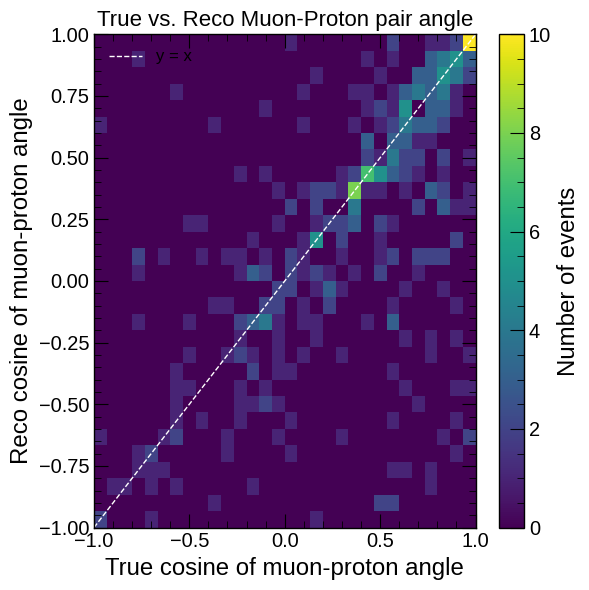

In [100]:
# First merge the true and reco dataframes on event_number to get only events that have both true and reco values
# These are events that pass both true and reco cuts
merged_true_reco = pd.merge(merged_true, merged_reco, on="event_number")

#print(merged_true_reco.head(10))

# ----------------------------------------------------------------------
# Muon-Proton pair angle (true)
# ----------------------------------------------------------------------
muon_proton_angles_true = []
event_numbers_true = []

for index, row in merged_true.iterrows():
    proton1 = [row["true_px_rank1"], row["true_py_rank1"], row["true_pz_rank1"]]
    proton2 = [row["true_px_rank2"], row["true_py_rank2"], row["true_pz_rank2"]]
    muon = [row["true_px_muon"], row["true_py_muon"], row["true_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles_true.append(angle)
    event_numbers_true.append(row["event_number"])

angle_df_true = pd.DataFrame({
    "event_number": event_numbers_true,
    "angle_true": muon_proton_angles_true,
})

# ----------------------------------------------------------------------
# Muon-Proton pair angle (reco)
# ----------------------------------------------------------------------
muon_proton_angles_reco = []
event_numbers_reco = []

for index, row in merged_reco.iterrows():
    proton1 = [row["reco_px_rank1"], row["reco_py_rank1"], row["reco_pz_rank1"]]
    proton2 = [row["reco_px_rank2"], row["reco_py_rank2"], row["reco_pz_rank2"]]
    muon = [row["reco_px_muon"], row["reco_py_muon"], row["reco_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles_reco.append(angle)
    event_numbers_reco.append(row["event_number"])

angle_df_reco = pd.DataFrame({
    "event_number": event_numbers_reco,
    "angle_reco": muon_proton_angles_reco,
})

# Merge true and reco angles on event number
angle_comparison = pd.merge(angle_df_true, angle_df_reco, on="event_number")

print(f"Number of events with both true and reco angle: {len(angle_comparison)}")

# 2D histogram: true vs. reco angle
plt.figure(figsize=(6, 6))

h = plt.hist2d(
    angle_comparison["angle_true"],
    angle_comparison["angle_reco"],
    bins=30,
    range=[[-1, 1], [-1, 1]],
    cmap="viridis",
)

plt.colorbar(h[3], label="Number of events")
plt.plot([-1, 1], [-1, 1], color="white", linestyle="--", linewidth=1, label="y = x")
plt.xlabel("True cosine of muon-proton angle")
plt.ylabel("Reco cosine of muon-proton angle")
plt.title("True vs. Reco Muon-Proton pair angle", fontsize=16)
plt.legend()
plt.tight_layout()
plt.show()

## Genie Reweighting
For each kinematic variables, fill a nominal histogram plus one histogram per universe for each knob, event by event

FSIReweight_G4BC: 6021 / 6021 events have weights
100 universes per event


/global/homes/z/zaemoore/.conda/envs/myenv/lib/python3.12/site-packages/awkward/_nplikes/array_module.py:313: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  result.shape = shape


  Leading Proton Momentum: nominal integral = 689.0
  Recoil Proton Momentum: nominal integral = 725.0
FSIReweight_hN: 6021 / 6021 events have weights
100 universes per event
  Leading Proton Momentum: nominal integral = 689.0
  Recoil Proton Momentum: nominal integral = 725.0
FSIReweight_INCL: 6021 / 6021 events have weights
100 universes per event
  Leading Proton Momentum: nominal integral = 689.0
  Recoil Proton Momentum: nominal integral = 725.0


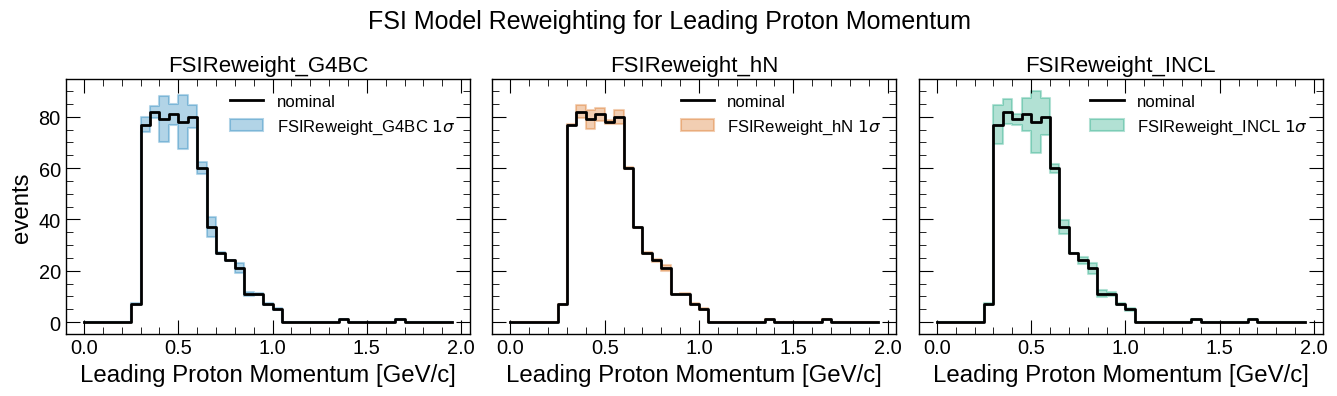

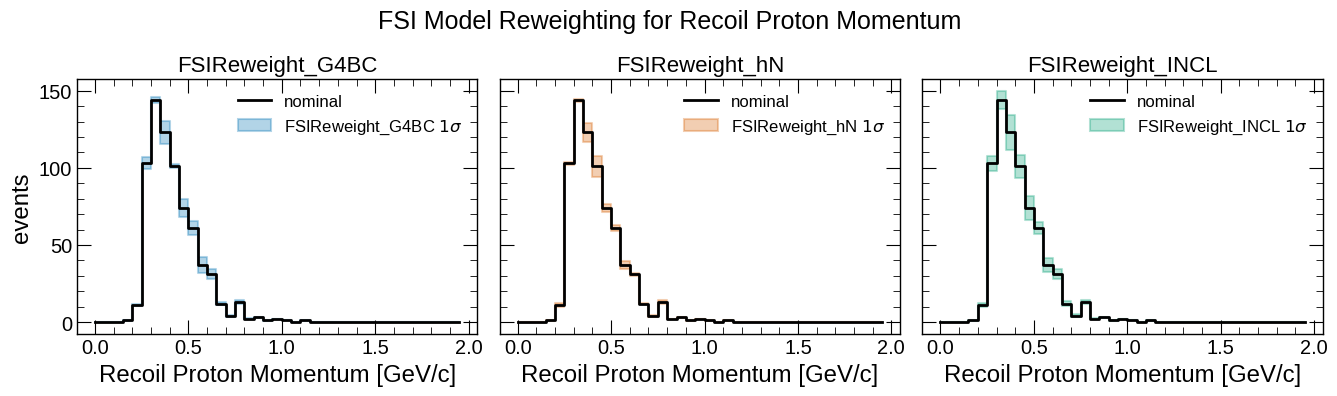

In [101]:
KNOBS = ["FSIReweight_G4BC", "FSIReweight_hN", "FSIReweight_INCL"]

KNOB_COLORS = {
    "FSIReweight_G4BC": "#0072B2",
    "FSIReweight_hN": "#D55E00",
    "FSIReweight_INCL": "#009E73",
}

# name -> (column in df, mask, nbins, xlo, xhi, x-axis label)
VARIABLES = {
    "Leading Proton Momentum": ("reco_pmag", (df["reco_proton_rank"] == 1) & (df["reco_passes"] == 1), 
        40, 0.0, 2.0, "Leading Proton Momentum [GeV/c]",),
    "Recoil Proton Momentum": ("reco_pmag", (df["reco_proton_rank"] == 2) & (df["reco_passes"] == 1),
        40, 0.0, 2.0, "Recoil Proton Momentum [GeV/c]")
}

# The nominal only depends on the kinematics, not the knob, so it's filled
# once per variable and reused for every knob's overlay.
results = {
    name: {"h_nom": None, "bands": {}}
    for name in VARIABLES
}

# ----------------------------------------------------------------------
# Fill histogram with weights for each variable for every KNOB
# ----------------------------------------------------------------------
for tune in KNOBS:

    # Load this knob's weights and check them before filling anything
    w_jagged = tree[tune].array(library="ak")   # noqa: F821
    counts = ak.to_numpy(ak.num(w_jagged))
    n_events = len(counts)

    print(f"{tune}: {(counts > 0).sum()} / {n_events} events have weights")
    if (counts > 0).sum() == 0:
        raise RuntimeError(
            f"{tune} is empty for every event in this file. The branch exists "
            "but the CAF-making step never filled it -- there is nothing to "
            "reweight with. Fix that upstream before plotting."
        )

    n_univ = int(counts.max())
    print(f"{n_univ} universes per event")

    w = ak.to_numpy(ak.fill_none(ak.pad_none(w_jagged, n_univ, axis=1), 1.0))
    bad = ~np.isfinite(w)
    if bad.any():
        print(f"WARNING: {bad.sum()} non-finite weights -> set to 1.0")
        w[bad] = 1.0

    # For each variable: nominal (once) + this knob's universes
    for name, (col, mask, nbins, xlo, xhi, xlabel) in VARIABLES.items():
        event_idx = df.loc[mask, "event_number"].to_numpy(dtype=int)   # noqa: F821
        values = df.loc[mask, col].to_numpy(dtype=float)   # noqa: F821
        assert len(values) == len(event_idx)

        if results[name]["h_nom"] is None:
            h_nom = Hist1D(nbins, xlo, xhi)
            for x in values:
                h_nom.Fill(x, 1.0)
            results[name]["h_nom"] = h_nom
            results[name]["xlabel"] = xlabel

        h_univ = [Hist1D(nbins, xlo, xhi) for _ in range(n_univ)]
        for x, i in zip(values, event_idx):
            for u in range(n_univ):
                h_univ[u].Fill(x, w[i, u])

        results[name]["bands"][tune] = h_univ
        print(f"  {name}: nominal integral = {results[name]['h_nom'].Integral():.1f}")


# ----------------------------------------------------------------------
# Plot systematic spread for each knob in separate variable plots
# ----------------------------------------------------------------------
for name, info in results.items():
    h_nom = info["h_nom"]
    nom = h_nom.contents
    tunes = list(info["bands"].keys())
 
    fig, axes = plt.subplots(
        1, len(tunes), figsize=(4.5 * len(tunes), 4), sharey=True,
    )
    if len(tunes) == 1:
        axes = [axes]
 
    for ax, tune in zip(axes, tunes):
        h_univ = info["bands"][tune]
        univ = np.array([h.contents for h in h_univ])   # (n_univ, nbins)
        syst = univ.std(axis=0, ddof=1)                  # 1 sigma across universes
 
        ax.step(h_nom.edges[:-1], nom, where="post", color="k", label="nominal")
        ax.fill_between(
            h_nom.edges[:-1], nom - syst, nom + syst,
            step="post", alpha=0.3, color=KNOB_COLORS.get(tune),
            label=f"{tune} $1\\sigma$",
        )
 
        ax.set_title(tune, fontsize=16)
        ax.set_xlabel(info["xlabel"])
        ax.legend()
 
    axes[0].set_ylabel("events")
    fig.suptitle(f"FSI Model Reweighting for {name}", fontsize=18)
    fig.tight_layout()
    plt.show()

## Kinematics weighted by GENIE Model variables

Leading Proton Momentum: nominal integral = 688.0


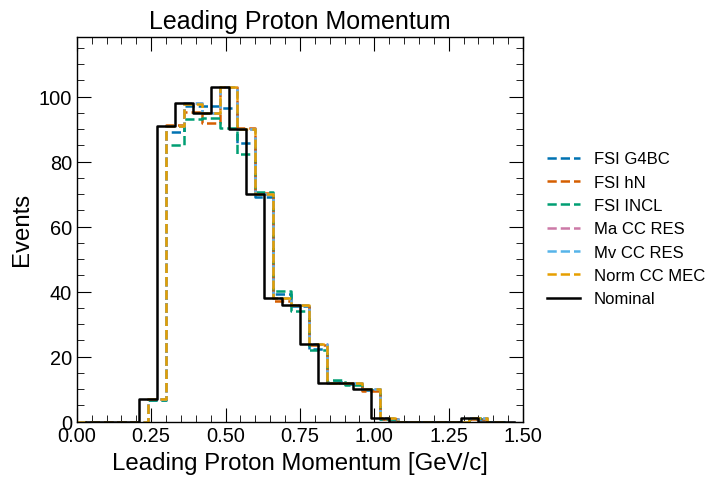

Recoil Proton Momentum: nominal integral = 725.0


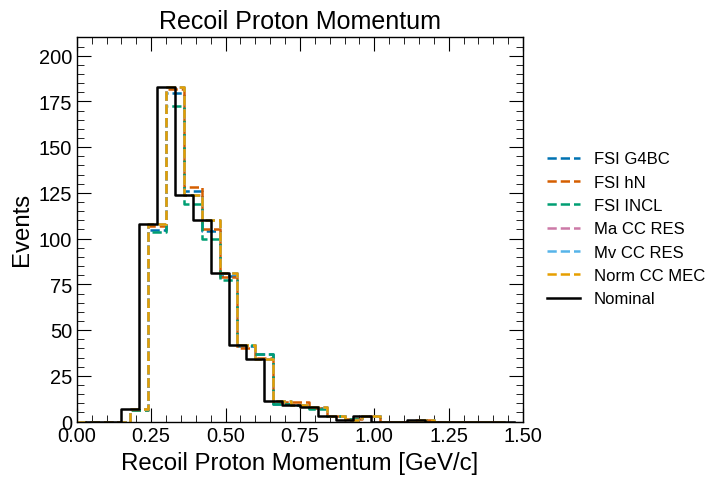

Muon Momentum: nominal integral = 943.0


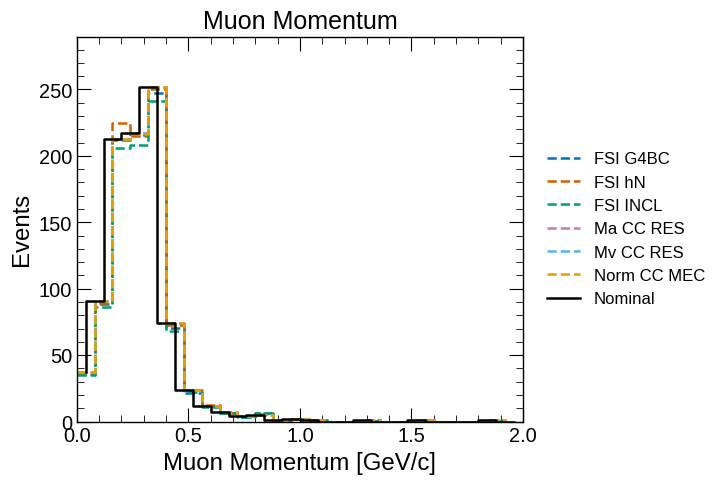

In [102]:
KNOBS = ["FSIReweight_G4BC", "FSIReweight_hN", "FSIReweight_INCL",
         "MaCCRES", "MvCCRES", "NormCCMEC"]

STYLES = {
    "FSIReweight_G4BC": dict(color="#0072B2", ls="--", label=r"FSI G4BC"),
    "FSIReweight_hN":   dict(color="#D55E00", ls="--", label=r"FSI hN"),
    "FSIReweight_INCL": dict(color="#009E73", ls="--", label=r"FSI INCL"),
    "MaCCRES":          dict(color="#CC79A7", ls="--", label=r"Ma CC RES"),
    "MvCCRES":          dict(color="#56B4E9", ls="--", label=r"Mv CC RES"),
    "NormCCMEC":        dict(color="#E69F00", ls="--", label=r"Norm CC MEC"),
}

# name -> (column in df, mask, nbins, xlo, xhi, x-axis label)
VARIABLES = {
    "Leading Proton Momentum": (
        "reco_pmag",
        (df["reco_proton_rank"] == 1) & (df["reco_passes"] == 1),   # noqa: F821
        25, 0.0, 1.5, "Leading Proton Momentum [GeV/c]",
    ),
    "Recoil Proton Momentum": (
        "reco_pmag",
        (df["reco_proton_rank"] == 2) & (df["reco_passes"] == 1),   # noqa: F821
        25, 0.0, 1.5, "Recoil Proton Momentum [GeV/c]",
    ),
    "Muon Momentum": ("reco_pmag", (df["reco_pdg"].abs() == 13) & (df["reco_passes"] == 1),
                   25, 0.0, 2.0, "Muon Momentum [GeV/c]"),
}

# Load every knob's weights ONCE, up front
knob_weights = {}   # tune -> (n_univ, w)


# ----------------------------------------------------------------------
# Fill weights for each knob for all universes
# ----------------------------------------------------------------------
for tune in KNOBS:
    w_jagged = tree[tune].array(library="ak")   # noqa: F821
    counts = ak.to_numpy(ak.num(w_jagged))

    if (counts > 0).sum() == 0:
        print(f"{tune}: empty for every event -- skipping")
        continue

    n_univ = int(counts.max())
    w = ak.to_numpy(ak.fill_none(ak.pad_none(w_jagged, n_univ, axis=1), 1.0))
    w[~np.isfinite(w)] = 1.0

    knob_weights[tune] = (n_univ, w)

# ----------------------------------------------------------------------
# For each variable: fill nominal + each knob's CV, then plot
# ----------------------------------------------------------------------
for name, (col, mask, nbins, xlo, xhi, xlabel) in VARIABLES.items():

    event_idx_all = df.loc[mask, "event_number"].to_numpy(dtype=int)   # noqa: F821
    values_all = df.loc[mask, col].to_numpy(dtype=float)               # noqa: F821

    edges = np.linspace(xlo, xhi, nbins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    # "Nominal": unweighted counts
    h_nom = Hist1D(nbins, xlo, xhi)
    for x in values_all:
        h_nom.Fill(x, 1.0)
    nom = h_nom.contents

    # each knob's central value: mean over that knob's universes
    cv_by_knob = {}
    for tune, (n_univ, w) in knob_weights.items():
        h_univ = [Hist1D(nbins, xlo, xhi) for _ in range(n_univ)]
        for x, i in zip(values_all, event_idx_all):
            for u in range(n_univ):
                h_univ[u].Fill(x, w[i, u])

        univ = np.array([h.contents for h in h_univ])   # (n_univ, nbins)
        cv_by_knob[tune] = univ.mean(axis=0)

    print(f"{name}: nominal integral = {nom.sum():.1f}")

    # Plot
    fig, ax = plt.subplots(figsize=(7.5, 5))

    for tune, cv in cv_by_knob.items():
        style = STYLES.get(tune, {})
        ax.step(edges[:-1], cv, where="post", linewidth=1.8, **style)

    ax.step(centers, nom, color="black", linewidth=1.8, label="Nominal")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Events")
    ax.set_xlim(xlo, xhi)
    ymax = max(nom.max(), max((cv.max() for cv in cv_by_knob.values()), default=0))
    ax.set_ylim(0, ymax * 1.15 if ymax > 0 else 1)
    ax.set_title(name, fontsize=18)

    # legend boxed outside to the right, like the reference figure
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.subplots_adjust(right=0.72)

    plt.show()

## Fractional Systematic Uncertainty
All reweight knobs on one plot <br>
CV(bin) = central value = mean over that knob's N universes <br>
sigma(bin) = std over that knob's N universes <br>
frac(bin) = fractional uncertainty = sigma(bin) / CV(bin) <br>
Total(bin) = sqrt(sum over knobs frac_k(bin)^2) 

FSIReweight_G4BC: 100 universes, mean fractional unc = 0.038
FSIReweight_hN: 100 universes, mean fractional unc = 0.021
FSIReweight_INCL: 100 universes, mean fractional unc = 0.045
genie_weights: 100 universes, mean fractional unc = 0.167


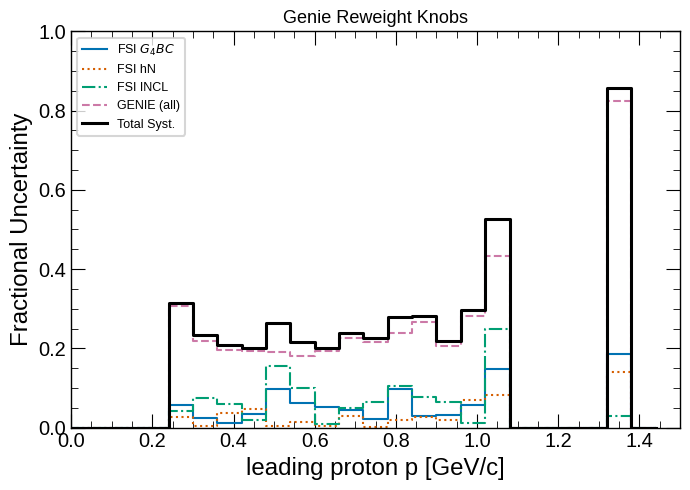

In [103]:
KNOBS = ["FSIReweight_G4BC", "FSIReweight_hN", "FSIReweight_INCL", "genie_weights"]

STYLES = {
    "FSIReweight_G4BC": dict(color="#0072B2",     ls="-",   label=r"FSI $G_4BC$"),
    "FSIReweight_hN":   dict(color="#D55E00",    ls=":",   label=r"FSI hN"),
    "FSIReweight_INCL": dict(color="#009E73", ls="-.",  label=r"FSI INCL"),
    "genie_weights":    dict(color="#CC79A7", ls="--", label="GENIE (all)"),
}

VARIABLE = ("reco_pmag",
            (df["reco_proton_rank"] == 1) & (df["reco_passes"] == 1), 
            25, 0.0, 1.5, "leading proton p [GeV/c]")


col, mask, nbins, xlo, xhi, xlabel = VARIABLE
event_idx_all = df.loc[mask, "event_number"].to_numpy(dtype=int)   # noqa: F821
values_all = df.loc[mask, col].to_numpy(dtype=float)               # noqa: F821

# ----------------------------------------------------------------------
# Fill CV + sigma per knob, skipping knobs with no weights
# ----------------------------------------------------------------------
frac_by_knob = {}
edges = np.linspace(xlo, xhi, nbins + 1)

for tune in KNOBS:
    w_jagged = tree[tune].array(library="ak")   # noqa: F821
    counts = ak.to_numpy(ak.num(w_jagged))

    if (counts > 0).sum() == 0:
        print(f"{tune}: empty for every event -- skipping")
        continue

    n_univ = int(counts.max())
    w = ak.to_numpy(ak.fill_none(ak.pad_none(w_jagged, n_univ, axis=1), 1.0))
    w[~np.isfinite(w)] = 1.0

    h_univ = [Hist1D(nbins, xlo, xhi) for _ in range(n_univ)]
    for x, i in zip(values_all, event_idx_all):
        for u in range(n_univ):
            h_univ[u].Fill(x, w[i, u])

    univ = np.array([h.contents for h in h_univ])   # (n_univ, nbins)
    cv = univ.mean(axis=0)
    sigma = univ.std(axis=0, ddof=1)

    with np.errstate(invalid="ignore", divide="ignore"):
        frac = np.where(cv > 0, sigma / cv, 0.0)

    frac_by_knob[tune] = frac
    print(f"{tune}: {n_univ} universes, mean fractional unc = {frac.mean():.3f}")


# Total = quadrature sum across knobs
total = np.sqrt(np.sum([f**2 for f in frac_by_knob.values()], axis=0))


# Plot -- step lines, styled like the reference figure
fig, ax = plt.subplots(figsize=(7, 5))

for tune, frac in frac_by_knob.items():
    style = STYLES.get(tune, {})
    ax.step(edges[:-1], frac, where="post", linewidth=1.5, **style)

ax.step(edges[:-1], total, where="post", color="black", linewidth=2.2,
        label="Total Syst.")

ax.set_xlabel(xlabel)
ax.set_ylabel("Fractional Uncertainty")
ax.set_ylim(0, max(1.0, total.max() * 1.1))
ax.set_xlim(xlo, xhi)
ax.legend(loc="upper left", frameon=True, fontsize=9)
ax.set_title("Genie Reweight Knobs", fontsize=13)
plt.tight_layout()
plt.show()

## Systematic Errors

Just plot the genie error weights per event?

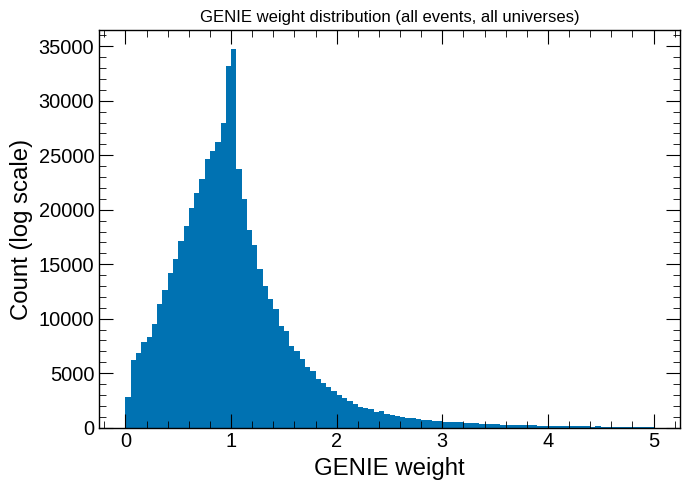

In [104]:
genie_weights = tree["genie_weights"].array(library="ak") 
ev1_wgts = genie_weights[0] # Weights for the first event (all universes)
# Flatten across all events/universes into one 1D array
flat_weights = ak.to_numpy(ak.flatten(genie_weights))

plt.figure(figsize=(7, 5))
plt.hist(flat_weights, bins=100, range=(0, 5), edgecolor="none")
#plt.yscale("log")
plt.xlabel("GENIE weight")
plt.ylabel("Count (log scale)")
plt.title("GENIE weight distribution (all events, all universes)", fontsize=12)
plt.tight_layout()
plt.show()

## Single Bin Cross Section

$\sigma = \frac{N_{obs}-N_{background} }{N_{target} \Phi \epsilon}$ <br>
Number of observed candidate events <br>
Number of estimated background events <br>
Number of target nuclei in the active volume of the detector <br>
Integrated neutrino flux <br>
Detector selection efficiency <br>

In [105]:
# Try this with the 3 hours of sandbox data

n_obs = sum(reco_event)  # Number of observed candidate events (This will be data only)
n_bg = sum(reco_event) - sum(true_reco_event)  # Number of background events (This will be monte carlo)
n_t = 1 # Number of target nuclei in the active volume (placeholder value, replace with actual number)
phi = 1 # cm^-2 Integrated neutrino flux (placeholder value, replace with actual flux)
eff = efficiency  # Detector selection efficiency (calculated above)

# ----------------------------------------------------------------------
# Number of target nuclei in the active volume calculation
# n_t = volume * density * avogadro_number / molar_mass 
# Use fiducial volume (containment cut)
# ----------------------------------------------------------------------
vol = 2 * (63.931 - 8) * 2 * (62.076 - 8) * 2 * (64.3163 - 8) #volume of tpc in cm^3, subtracting 8 cm from each side for containment cut
n_avo = 6.022e23 #avogadro's number
density = 1.4 #g/cm^3 for liquid argon approximately
molar_mass = 39.948 #g/mol for liquid argon
#n_t = vol * density * n_avo / molar_mass # Number of target nuclei in the active volume
n_t = 2.825846E28 # Referenced from the 2x2 CC Muon Neutrino Selection paper, this number accounts for dead space between modules
print("Number of target atoms: ", n_t)

# ----------------------------------------------------------------------
# Integrated flux calculation from numi flux file
# ----------------------------------------------------------------------
flux_file = uproot.open("numiFluxSystFull.root")

def get_flux_hist(species, mode="rhc", corrected=True):
    """species: 'numu', 'numubar', 'nue', 'nuebar'"""
    tag = "ppfx_corrected" if corrected else "nominal"
    name = f"hflux_{mode}_{species}_{tag}"
    h = flux_file[name]
    values = h.values()          # per-bin flux content (array, len = n_bins)
    edges  = h.axis().edges()    # bin edges in true neutrino energy [GeV]
    return values, edges

def integrated_flux_shape(species_list, mode="rhc", e_lo=None, e_hi=None):
    """
    Sum the flux histograms for one or more species over an energy range.
    e_lo/e_hi in GeV; leave as None to integrate the full spectrum.
    Returns the integral in whatever units the file's bin content is in
    """
    total = 0.0
    for species in species_list:
        values, edges = get_flux_hist(species, mode=mode)
        lo_idx = 0 if e_lo is None else np.searchsorted(edges, e_lo)
        hi_idx = len(values) if e_hi is None else np.searchsorted(edges, e_hi)
        total += values[lo_idx:hi_idx].sum()
    return total

flux_shape = integrated_flux_shape(["numu", "numubar"])
# Apply your POT normalization
mc_POT = 1e19          # POT of flux file
run1_POT      = 1.1E19        # POT of run 1

# This is ONLY MC, so it makes sense to only multiply by the mc_POT
phi = flux_shape * mc_POT# Integrated neutrino flux in cm^-2

print(f"Integrated flux (phi):      {phi:.6e}  nu/cm^2")
print(n_t)
print(eff)
xsec = (n_obs - n_bg) / (n_t * phi * eff)  # Cross-section calculation
print("Single bin cross section: ", xsec)
#10e-38 order makes sense

Number of target atoms:  2.825846e+28
Integrated flux (phi):      5.637004e+15  nu/cm^2
2.825846e+28
0.3291139240506329
Single bin cross section:  6.447236384498141e-42
